# Fase 4 · Proyecto integrador TMDB (2010–2025) — Grupo 4
## Del problema original a la evaluación final: decisiones, evidencias y límites

**Propósito.** Reconstruir el camino seguido por el Grupo 4 desde la definición de la pregunta (F1), la preparación del catálogo (F2) y la construcción del núcleo algorítmico (F3), hasta una evaluación explicativa y reproducible (F4). No se trata de acumular gráficos: cada figura debe responder una pregunta y motivar la siguiente decisión.

**Regla de procedencia.** El repositorio público [`yetgx/mcdi500-tmdb-grupo4`](https://github.com/yetgx/mcdi500-tmdb-grupo4), rama `main`, es la referencia del proyecto. Este cuaderno se ejecuta dentro de un clon; su commit se registra para distinguir una medición reproducible de una versión simplemente descrita. La retroalimentación docente solicita expresamente **reutilizar los artefactos finales de F3**, analizar 3.596 consultas, justificar los pesos 0,5/0,5, construir intervalos bootstrap por consulta, estudiar sesgos por idioma, diversidad y casos concretos.

**Criterio académico.** Cuando no hay un archivo que demuestre una cifra o decisión, el notebook la identifica como *no verificada*, sin sustituirla por una cifra inventada. Las conclusiones cuantitativas se generan de las salidas efectivamente obtenidas.

## El recorrido completo: una decisión condujo a la siguiente

La trayectoria del Grupo 4 no puede explicarse como cuatro entregas independientes. La definición de *qué* recomendar determinó *qué* información conservar; las dificultades de representación condicionaron *cómo* calcular similitudes; la necesidad de mantener un procesamiento comprobable llevó a modularizarlo; y las métricas inicialmente planteadas determinaron *qué* visualizar al cierre.

| Momento | Pregunta que surgió | Respuesta técnica verificable | Consecuencia para la fase siguiente |
|---|---|---|---|
| **F1 · Planteamiento** | ¿Qué significa una recomendación coherente? | Tres indicadores: género, idioma y votos, comparables con azar | Define las variables y relaciones que F2 debe preservar |
| **F2 · Preparación** | ¿Cómo convertir metadatos heterogéneos en datos procesables sin perder la identidad de cada película? | Limpieza, `movie_id`, `metadata_soup`, CSV procesado y Bag of Words disperso | Hace posibles comparaciones vectoriales y atributos interpretables |
| **F3 · Ingeniería** | ¿Cómo reducir el acoplamiento y verificar costo temporal y espacial? | Módulos, transformadores, pruebas y benchmark | Permite auditar el camino algorítmico antes de interpretar resultados |
| **F4 · Síntesis** | ¿Qué evidencia existe a favor del enfoque y cuáles son sus límites? | Control aleatorio, resultados por indicador, gráficos y discusión | Permite responder la pregunta inicial sin confundir asociación con satisfacción |



## Capítulo 1 · Fase 1: de la necesidad de recomendar a una pregunta que puede ponerse a prueba

El proyecto surgió de una dificultad habitual en catálogos extensos: que dos películas resulten «parecidas» no constituye por sí mismo una definición operativa. Para construir una solución defendible, el Grupo 4 necesitaba acordar qué características de una sugerencia podían medirse y cómo distinguir una recomendación informada de una selección fortuita.

**Primera decisión documentada.** El planteamiento publicado por el equipo considera similitud de contenido —incluidos géneros, productoras e idioma— combinada con señales de calidad y popularidad. Para evaluar resultados se establecieron **tres propiedades observables** de un conjunto top-10: compartir al menos un género, coincidir en idioma original y alcanzar un volumen de votos situado por encima del percentil 75 del catálogo. Una línea base aleatoria ofrece contexto para las proporciones observadas.

**Por qué esta decisión fue necesaria.** La afinidad temática, la consistencia lingüística y el respaldo de votos representan dimensiones diferentes. Un modelo podría proponer títulos del mismo género y, aun así, recomendar obras poco conocidas; o priorizar títulos muy votados pero alejados de la consulta. Separar indicadores permite detectar esos compromisos, en lugar de esconderlos en una puntuación única.

**Qué se obtiene en esta fase.** Se establece un criterio de éxito comprobable; todavía **no** se demuestra que los usuarios prefieran las recomendaciones. Los votos miden participación y el género o el idioma son aproximaciones basadas en metadatos. Esta distinción determina cómo interpretaremos los resultados al final del recorrido.

**Transición hacia F2.** Una vez definido lo que queríamos comparar, fue necesario preparar los metadatos sin perder la correspondencia entre cada película y sus atributos originales.

In [1]:
from pathlib import Path
import os
import sys
import platform
import subprocess
import json
import inspect
import importlib
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display, Markdown

# ============================================================
# 1. CONFIGURACIÓN DE REPRODUCIBILIDAD
# ============================================================

SEMILLA = 42
rng = np.random.default_rng(SEMILLA)

# ============================================================
# 2. IDENTIFICACIÓN DE LA RAÍZ DEL REPOSITORIO
# ============================================================

RAIZ = next(
    (
        p for p in [Path.cwd(), *Path.cwd().parents]
        if (p / "README.md").exists()
        and (p / "F1").is_dir()
        and (p / "F2").is_dir()
        and (p / "F3").is_dir()
    ),
    None
)

if RAIZ is None:
    raise FileNotFoundError(
        "No se encontró la raíz del proyecto. "
        "Abra el notebook dentro del repositorio "
        "mcdi500-tmdb-grupo4."
    )

# ============================================================
# 3. FUNCIÓN PARA CONSULTAR INFORMACIÓN DE GIT
# ============================================================

def git(*args):
    """Ejecuta una consulta Git desde la raíz del proyecto."""
    return subprocess.check_output(
        ["git", "-C", str(RAIZ), *args],
        text=True,
        encoding="utf-8",
        errors="replace"
    ).strip()

# ============================================================
# 4. IDENTIFICACIÓN DE RAMA Y COMMITS
# ============================================================

try:
    rama = git("branch", "--show-current")
    head = git("rev-parse", "HEAD")
except (subprocess.CalledProcessError, FileNotFoundError) as e:
    raise RuntimeError(
        "No fue posible consultar Git. "
        "Verifique que el proyecto sea un repositorio válido."
    ) from e

try:
    remoto = git("rev-parse", "--verify", "refs/remotes/origin/main")
except (subprocess.CalledProcessError, FileNotFoundError):
    remoto = None

# ============================================================
# 5. IDENTIFICACIÓN TÉCNICA DEL PROYECTO COLECTIVO
# ============================================================
print("=" * 65)
print("MCDI500 | PROYECTO INTEGRADOR TMDB | GRUPO 4")
print("Fase 4: análisis y comunicación de resultados")
print("=" * 65)
print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__, "| NumPy:", np.__version__)
print("Entorno virtual activo:", sys.prefix != sys.base_prefix)
print("Semilla de reproducibilidad:", SEMILLA)

# La identidad del commit se conserva para auditoría del trabajo grupal.
# No se muestra el nombre de la rama personal como hallazgo científico.
print("\n=== REGISTRO DE TRAZABILIDAD COLECTIVA ===")
print("Repositorio público: yetgx/mcdi500-tmdb-grupo4")
print("Versión de código ejecutada (commit):", head[:12])
if remoto and remoto == head:
    print("El commit coincide con la referencia local origin/main.")
else:
    print("AVISO: no está demostrada la coincidencia con el último main remoto.")
    print("La referencia origin/main es local y puede requerir actualización.")
print("La información de rama puede auditarse con Git sin integrarla al relato de hallazgos.")

# ============================================================
# 7. VERIFICACIÓN DE ARCHIVOS DE ENTRADA
# ============================================================

print("\n=== VERIFICACIÓN DE DATOS ===")

RUTA_RAW = RAIZ / "data" / "raw" / "movies_raw.csv"

if not RUTA_RAW.is_file():
    raise FileNotFoundError(
        f"No se encontró el dataset original:\n{RUTA_RAW}"
    )

if RUTA_RAW.stat().st_size == 0:
    raise ValueError(
        "El archivo movies_raw.csv existe, pero está vacío."
    )

print(f"Dataset localizado: {RUTA_RAW.relative_to(RAIZ).as_posix()}")
print(f"Tamaño del archivo: {RUTA_RAW.stat().st_size:,} bytes")

print("\nVerificación inicial del entorno: COMPLETADA.")
print("El contenido del dataset se validará en la siguiente etapa.")

MCDI500 | PROYECTO INTEGRADOR TMDB | GRUPO 4
Fase 4: análisis y comunicación de resultados
Python: 3.13.0
pandas: 3.1.1 | NumPy: 2.5.4
Entorno virtual activo: True
Semilla de reproducibilidad: 42

=== REGISTRO DE TRAZABILIDAD COLECTIVA ===
Repositorio público: yetgx/mcdi500-tmdb-grupo4
Versión de código ejecutada (commit): 56a1f42d499e
AVISO: no está demostrada la coincidencia con el último main remoto.
La referencia origin/main es local y puede requerir actualización.
La información de rama puede auditarse con Git sin integrarla al relato de hallazgos.

=== VERIFICACIÓN DE DATOS ===
Dataset localizado: data/raw/movies_raw.csv
Tamaño del archivo: 3,363,326 bytes

Verificación inicial del entorno: COMPLETADA.
El contenido del dataset se validará en la siguiente etapa.


### Primera decisión transversal: documentar condiciones reproducibles, sin personalizar la historia

Una investigación desarrollada por varias personas necesita que el código y sus resultados sean identificables. Por eso el proyecto se apoya en control de versiones, dependencias explícitas y una semilla de aleatoriedad. La primera celda registra las versiones de Python, pandas y NumPy, detecta el entorno virtual, localiza el repositorio y comprueba que el archivo original exista y no esté vacío.

**Lectura de la evidencia.** Esta comprobación establece las condiciones técnicas mínimas para interpretar las operaciones posteriores; **no certifica** que la recomendación sea buena ni, por sí sola, que todos los resultados sean reproducibles. Un commit identifica una versión de código; además se requiere verificar sus entradas y ejecutar todas las celdas sin errores.

**Decisión del Grupo 4.** La trazabilidad se mantiene como información técnica auditable, mientras que el texto académico se concentra en la evolución colectiva. No se presentan ramas personales ni identidades de trabajo en los hallazgos, porque no explican por qué se limpiaron los datos, se eligió una representación o se compararon los algoritmos.

**Consecuencia.** Con las condiciones de ejecución identificadas, podemos estudiar los datos y comprobar si la información de partida es adecuada para los tres criterios que definió F1.

In [2]:
criterios = pd.DataFrame([
  {'objetivo':'Género compartido','referencia_readme':0.418,'interpretación':'≥1 género en común'},
  {'objetivo':'Idioma coincidente','referencia_readme':0.366,'interpretación':'mismo idioma original'},
  {'objetivo':'Votos sobre P75','referencia_readme':0.250,'interpretación':'vote_count ≥ P75 catálogo'},
])
display(criterios.assign(referencia_pct=lambda d:(100*d.referencia_readme).round(1)))
print('Estos son valores de referencia de F1; todavía no son resultados de F4.')

,objetivo,referencia_readme,interpretación,referencia_pct
0,Género compartido,0.418,≥1 género en común,41.8
1,Idioma coincidente,0.366,mismo idioma original,36.6
2,Votos sobre P75,0.250,vote_count ≥ P75 catálogo,25.0


Estos son valores de referencia de F1; todavía no son resultados de F4.


### Qué enseñan las referencias de F1 y cómo condicionaron la investigación

La tabla anterior traduce el planteamiento inicial del equipo a tres indicadores comparables. Las tasas de **41,8 %** (género), **36,6 %** (idioma) y **25,0 %** (votos) figuran en el README como **referencias de partida**: no son resultados obtenidos por el protocolo experimental ejecutado aquí.

Su valor metodológico es concreto. Antes de construir o evaluar recomendaciones, el Grupo 4 dejó establecida una comparación que permite distinguir resultados atribuibles al método de coincidencias plausibles por azar. Además, cada indicador determina qué atributos debe conservar F2 y qué figura deberá comunicar F4. **La decisión siguiente, por tanto, no era dibujar un gráfico: era preparar un catálogo en el que estas tres preguntas pudieran responderse sin ambigüedad.**

## Capítulo 2 · Fase 2: comprender el catálogo antes de transformarlo

El punto de partida fue un conjunto de películas con variables de diferente naturaleza: identificadores, títulos, géneros, lenguas, votos, popularidad y metadatos textuales. Trabajar directamente sobre esas columnas habría dificultado tanto la comparación automática como la validación del tratamiento de valores faltantes. El desafío consistió en **limpiar y transformar sin destruir la identidad ni la interpretación de cada película**.

**Decisión observable del equipo.** En F2 se generó un conjunto procesado, se conservaron claves `movie_id` y se construyeron atributos que posteriormente alimentan la similitud y las puntuaciones de recomendación. El archivo original permanece sin modificación. Esta separación permite contrastar el punto de partida con el resultado de preparación y detectar pérdidas de registros o desalineaciones.

**Justificación.** Un recomendador necesita identificar inequívocamente cada película para excluir la consulta de sus propias sugerencias y unir las representaciones vectoriales con información legible. Si la limpieza altera el orden o elimina filas sin conservar correspondencias, una similitud numéricamente correcta puede terminar asociada al título equivocado.

**Evidencia a observar en la siguiente celda.** La comparación entre tamaños, cantidad y unicidad de identificadores y patrones de faltantes permite comprobar qué se conservó y qué variables requirieron atención. No interpretaremos la ausencia de cambios en el número de filas como prueba de que toda imputación fue acertada; solo demuestra que no se perdieron identificadores.

In [3]:
raw_path = RAIZ/'data/raw/movies_raw.csv'
proc_path = RAIZ/'data/processed/movies_procesado.csv'
assert proc_path.exists(), 'Falta el CSV procesado de F2 en main.'
raw = pd.read_csv(raw_path,low_memory=False)
proc = pd.read_csv(proc_path,low_memory=False)
assert 'movie_id' in raw and 'movie_id' in proc
assert raw.movie_id.is_unique and proc.movie_id.is_unique
assert raw.movie_id.notna().all() and proc.movie_id.notna().all()
assert set(raw.movie_id)==set(proc.movie_id), 'Los ID de F2 no coinciden con F1.'
print('F1 original:',raw.shape, '| F2 procesado:',proc.shape)
print('Identificadores únicos en F1/F2:',raw.movie_id.nunique(),proc.movie_id.nunique())
print('Orden de ID idéntico:',raw.movie_id.tolist()==proc.movie_id.tolist())
print('Columnas F2:',proc.columns.tolist())
print('Faltantes principales de origen:')
display(raw.isna().sum().sort_values(ascending=False).head(8).rename('faltantes').to_frame())
print('Tipos de los atributos numéricos clave:')
display(proc[[x for x in ['vote_average','vote_count','popularity','weighted_rating','score_quality_norm','score_popularity_norm'] if x in proc]].dtypes.rename('dtype').to_frame())

F1 original: (17978, 16) | F2 procesado: (17978, 16)
Identificadores únicos en F1/F2: 17978 17978
Orden de ID idéntico: True
Columnas F2: ['movie_id', 'title', 'release_date', 'genres_clean', 'companies_clean', 'lang_clean', 'metadata_soup', 'vote_average', 'vote_count', 'popularity', 'weighted_rating', 'score_quality_norm', 'score_popularity_norm', 'runtime_clean', 'budget_clean', 'revenue_clean']
Faltantes principales de origen:


,faltantes
production_companies,494
production_countries,176
spoken_languages,92
genres,10
status,0
movie_id,0
release_date,0
title,0


Tipos de los atributos numéricos clave:


,dtype
vote_average,float64
vote_count,int64
popularity,float64
weighted_rating,float64
score_quality_norm,float64
score_popularity_norm,float64


### Primer hallazgo de preparación: conservar películas no significa conservar los datos intactos

La lectura del CSV original y del procesado permite comprobar si se mantiene el universo de películas. En la ejecución aportada, **ambos conservaron 17.978 registros**, y las comprobaciones de identificadores confirmaron la correspondencia requerida para continuar el análisis. Este resultado es importante porque el sistema necesita relacionar las características originales con las nuevas variables que alimentan los algoritmos.

**Interpretación que justifica la decisión.** La preparación no consistió simplemente en «quitar filas malas»: el equipo optó por conservar la cobertura del catálogo y transformar su representación. La tabla de faltantes muestra dónde estaban las principales ausencias antes del tratamiento; los tipos de las nuevas columnas permiten comprobar qué atributos ya pueden procesarse matemáticamente. Estas observaciones explican por qué fue necesario un paso sistemático de transformación antes de construir recomendaciones.

**Consecuencia para el camino recorrido.** A partir de un catálogo con atributos heterogéneos se obtiene una estructura comparable, pero aún falta traducir metadatos textuales en una forma sobre la que pueda calcularse similitud. Esa necesidad explica la construcción de `metadata_soup` y Bag of Words.

**Límite.** La igualdad de IDs y filas no certifica por sí sola la pertinencia semántica de cada transformación; esa cuestión requiere inspección de funciones y pruebas específicas de F2.

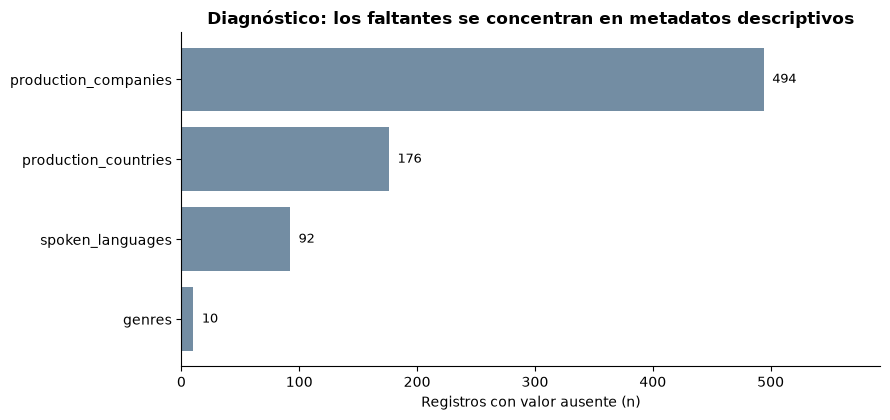

**Interpretación y consecuencia.** Se identificaron **4 campos con faltantes**; el más afectado fue **production_companies**, con **494** registros. Esta evidencia justifica una limpieza diferenciada y explica por qué las categorías deben normalizarse antes de construir la representación de similitud. **Límite:** una frecuencia de nulos no informa por sí sola la causa de ausencia ni permite inferir preferencias de los usuarios.

In [4]:
# Figura de diagnóstico. Los datos son los faltantes reales del CSV original.
faltantes = raw.isna().sum().sort_values(ascending=False)
con_faltantes = faltantes[faltantes.gt(0)].head(10).sort_values()
fig, ax = plt.subplots(figsize=(9, 4.3))
ax.barh(con_faltantes.index, con_faltantes.to_numpy(), color='#738DA3')
for y, n in enumerate(con_faltantes.to_numpy()):
    ax.text(n + max(2,con_faltantes.max()*.015), y, str(int(n)), va='center', fontsize=9)
ax.set_xlim(0, max(con_faltantes.max()*1.2, 1))
ax.set_xlabel('Registros con valor ausente (n)')
ax.set_title('Diagnóstico: los faltantes se concentran en metadatos descriptivos', weight='bold')
ax.spines[['right','top']].set_visible(False)
fig.tight_layout(); plt.show()
principal = faltantes[faltantes.gt(0)]
display(Markdown(f"**Interpretación y consecuencia.** Se identificaron **{len(principal)} campos con faltantes**; "
                 f"el más afectado fue **{principal.index[0]}**, con **{int(principal.iloc[0]):,}** registros. "
                 "Esta evidencia justifica una limpieza diferenciada y explica por qué las categorías deben "
                 "normalizarse antes de construir la representación de similitud. **Límite:** una frecuencia de nulos "
                 "no informa por sí sola la causa de ausencia ni permite inferir preferencias de los usuarios."))

### Una decisión distinta: datos para calcular no son datos para explicar

El dataset procesado facilita los cálculos, pero la interpretación de un informe necesita categorías legibles y valores con unidades originales. Por eso F4 utilizará una **tabla de visualización** recuperando géneros, idioma y votos originales y uniéndolos por `movie_id` con las filas procesadas. No “deshace” automáticamente todas las transformaciones ni presume que el valor normalizado sea un número de votos: **reconstruye una vista interpretable de forma controlada**.

## Capítulo 3 · F2: convertir atributos de películas en una representación comparable

Al completar la limpieza apareció una dificultad distinta. Géneros, productoras, idiomas y términos descriptivos son útiles para explicar una película, pero no pueden compararse directamente con operaciones vectoriales sin una codificación. El proyecto necesitaba **una representación común del contenido**.

**Decisión implementada.** F2 reunió atributos textuales en `metadata_soup` y generó una matriz Bag of Words (BOW). Cada fila corresponde a una película y cada columna a un término del vocabulario. Para no almacenar posiciones que valen cero, se conservó una representación **dispersa**. El código siguiente carga ese artefacto si existe y verifica que sus filas sigan correspondiendo a las películas del CSV procesado.

**Justificación y alternativa evitada.** Una matriz densa de todas las parejas de películas es innecesaria para responder consultas individuales; el producto del vector de la consulta por la matriz de términos permite recuperar puntuaciones sin reservar toda una matriz de similitud N×N. Esto condiciona la viabilidad de la etapa experimental de F4.

**Prueba relevante.** Las dimensiones, el número de elementos no nulos, la densidad y la memoria de la estructura CSR no son estadísticas decorativas: explican si la codificación aporta una base razonable para la comparación de contenido. Hay que distinguir esta representación de un aprendizaje semántico avanzado; BOW captura presencia o frecuencia de tokens, no comprensión del significado.

In [5]:
from scipy import sparse
from sklearn.preprocessing import normalize
from sklearn.feature_extraction.text import CountVectorizer
ruta_bow = RAIZ/'data/processed/movies_bow_matrix.npz'
if not ruta_bow.is_file():
    raise FileNotFoundError(
        f"Falta el artefacto F2 {ruta_bow}. F4 no reconstruye BOW: "
        "incorpore a main el artefacto preparado y verificable de F2."
    )
bow = sparse.load_npz(ruta_bow).tocsr()
origen_bow = str(ruta_bow.relative_to(RAIZ))
assert bow.shape[0]==len(proc), 'Filas BOW y CSV procesado no coinciden.'
bow = normalize(bow,norm='l2',axis=1).tocsr()
print('Representación:',origen_bow)
print('Forma matriz:',bow.shape,'| Entradas no nulas:',bow.nnz)
print('Densidad porcentual:',round(bow.nnz/(bow.shape[0]*bow.shape[1])*100,5))
print('Memoria estructuras CSR (MiB):',round((bow.data.nbytes+bow.indices.nbytes+bow.indptr.nbytes)/2**20,2))

Representación: data\processed\movies_bow_matrix.npz
Forma matriz: (17978, 13766) | Entradas no nulas: 102902
Densidad porcentual: 0.04158
Memoria estructuras CSR (MiB): 1.25


### Segundo hallazgo: la dispersidad hizo viable la comparación por contenido

La ejecución proporcionada registró una BOW de **17.978 películas por 13.766 atributos**, con una **densidad aproximada de 0,04158 %**. Es decir, casi todas las combinaciones entre película y término están vacías. Esta característica no representa un defecto del conjunto: refleja que cada película utiliza solo una pequeña parte del vocabulario global.

**Interpretación y decisión técnica.** Mantener la BOW en formato disperso evita representar explícitamente millones de posiciones cero. Por esa razón, el protocolo F4 calcula similitudes **consulta a catálogo**, en vez de construir de manera anticipada una matriz completa de similitudes entre todas las películas. Es una consecuencia concreta del diagnóstico de F2.

**Qué aporta al relato.** La información textual quedó convertida en una estructura numérica utilizable sin abandonar la correspondencia con `movie_id`. Este puente explica por qué F2 no termina con la limpieza: prepara el insumo sobre el que actúan los algoritmos y permite comprender el problema de eficiencia que aborda F3.

**Límite de la medición.** La densidad mide almacenamiento de términos, no calidad de las recomendaciones. Sus dimensiones deben verificarse nuevamente al ejecutar la versión definitiva de los artefactos de GitHub.

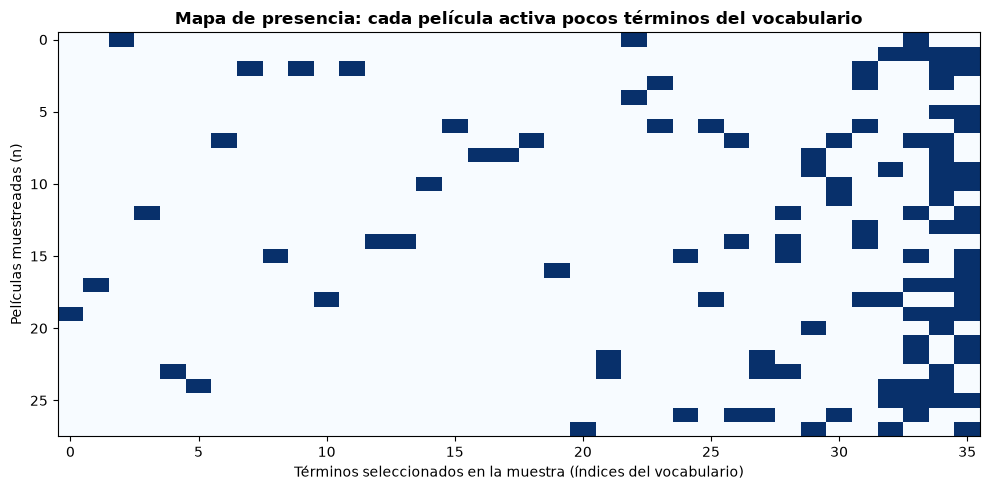

**Lectura de la figura.** En esta vista **deliberadamente seleccionada** de 28 películas y 36 términos, el **10.5 %** de las celdas es distinto de cero. No representa la densidad global: las columnas se eligieron por presencia en la muestra. La densidad global válida para el argumento de almacenamiento es la calculada en la celda anterior.

In [6]:
# Mapa de presencia de términos en una muestra reproducible: no crea una matriz densa global.
filas_muestra = np.random.default_rng(SEMILLA).choice(bow.shape[0], size=min(28,bow.shape[0]), replace=False)
frecuencia = np.asarray(bow[filas_muestra].getnnz(axis=0)).ravel()
columnas_muestra = np.argsort(frecuencia)[-min(36, np.count_nonzero(frecuencia)):]
submatriz = (bow[filas_muestra][:, columnas_muestra].toarray() > 0).astype(int)
fig, ax = plt.subplots(figsize=(10, 5))
ax.imshow(submatriz, aspect='auto', cmap='Blues', interpolation='nearest', vmin=0, vmax=1)
ax.set_xlabel('Términos seleccionados en la muestra (índices del vocabulario)')
ax.set_ylabel('Películas muestreadas (n)')
ax.set_title('Mapa de presencia: cada película activa pocos términos del vocabulario', weight='bold')
fig.tight_layout(); plt.show()
porcentaje_local = 100*submatriz.mean()
display(Markdown(f"**Lectura de la figura.** En esta vista **deliberadamente seleccionada** de "
                 f"{submatriz.shape[0]} películas y {submatriz.shape[1]} términos, "
                 f"el **{porcentaje_local:.1f} %** de las celdas es distinto de cero. "
                 "No representa la densidad global: las columnas se eligieron por presencia en la muestra. "
                 "La densidad global válida para el argumento de almacenamiento es la calculada en la celda anterior."))

## Capítulo 4 · Fase 3: pasar de un procesamiento funcional a un núcleo algorítmico defendible

La etapa siguiente no consistió simplemente en ejecutar transformaciones sobre un DataFrame. Una vez que el proyecto creció, se hizo necesario separar responsabilidades, reutilizar componentes y demostrar que el costo de procesamiento se conocía. El reto pasó de **obtener un resultado** a **obtenerlo de una manera comprobable y mantenible**.

**Decisiones observables.** En `src/` el proyecto organiza tareas de carga, preparación, transformaciones, pipeline y medición. La fase incluye transformadores orientados a objetos y pruebas asociadas a módulos; también deja resultados empíricos para comparar enfoques de procesamiento. Estas evidencias sustentan el relato colectivo mejor que atribuir el trabajo a un integrante o a una rama particular.

**Justificación arquitectónica.** Separar responsabilidades reduce la necesidad de editar múltiples bloques cuando cambia una transformación. El encapsulamiento y el polimorfismo permiten mantener una interfaz homogénea para distintas operaciones; las pruebas sirven para advertir regresiones y el benchmark obliga a evaluar rendimiento bajo condiciones observadas.

**Pregunta que plantearon los resultados.** ¿La opción más rápida también consume menos memoria? La siguiente celda estudia esa compensación antes de atribuir superioridad general a un método.

In [7]:
print('Módulos disponibles en el repositorio del proyecto:')
modulos = sorted(p.name for p in (RAIZ/'src').glob('*.py'))
pruebas = sorted(p.name for p in (RAIZ/'tests').glob('test_*.py'))
print(', '.join(modulos))
print('Pruebas en main:',', '.join(pruebas))
print('Existe implementacion del recomendador:', (RAIZ/'src/recomendador.py').exists())

def es(x, d=2):
    """Formato es-CL: punto para miles, coma para decimales."""
    return f"{x:,.{d}f}".translate({44: '.', 46: ','})

ruta_med = RAIZ/'F3/results/mediciones.csv'
if not ruta_med.is_file():
    raise FileNotFoundError('Falta F3/results/mediciones.csv; ejecutar F3.')
med = pd.read_csv(ruta_med)
esperadas = {'versión', 'tiempo_s', 'memoria_pico_MB', 'experimento', 'n'}
if not esperadas <= set(med.columns):
    raise ValueError(f'mediciones.csv no tiene las columnas {sorted(esperadas - set(med.columns))}.')
print('Mediciones F3:', ruta_med.relative_to(RAIZ).as_posix())
display(med.groupby('experimento', sort=False).agg(
    versiones=('versión', 'nunique'), tamaños=('n', lambda s: ', '.join(es(v, 0) for v in sorted(s.unique())))))

sopa = med[med['experimento'].eq('sopa')].set_index('versión')
t_iter, t_col = sopa.loc['bucle iterrows', 'tiempo_s'], sopa.loc['por columnas (clase)', 'tiempo_s']
m_iter, m_col = sopa.loc['bucle iterrows', 'memoria_pico_MB'], sopa.loc['por columnas (clase)', 'memoria_pico_MB']
n_sopa = int(sopa['n'].iloc[0])
print(f"Interpretación automática: con {es(n_sopa, 0)} registros, por columnas fue {es(t_iter/t_col)} veces más rápida "
      f"y su pico de memoria rastreada fue {es(m_col/m_iter)} veces el de iterrows.")

Módulos disponibles en el repositorio del proyecto:
carga.py, comunicacion.py, f4_puntos_5_7.py, medicion.py, pipeline.py, preparacion.py, recomendador.py, recursividad.py, transformadores.py
Pruebas en main: test_carga.py, test_f4_puntos_5_7.py, test_medicion.py, test_pipeline.py, test_preparacion.py, test_recomendador.py, test_recursividad.py, test_transformadores.py
Existe implementacion del recomendador: True
Mediciones F3: F3/results/mediciones.csv


,versiones,tamaños
experimento,,
sopa,2,14.382
coseno,2,17.978
top_k,4,"1.000, 2.000, 4.000, 8.000, 17.978"
aplanar,2,"1.000, 2.000, 4.000, 8.000, 17.978"


Interpretación automática: con 14.382 registros, por columnas fue 4,86 veces más rápida y su pico de memoria rastreada fue 1,24 veces el de iterrows.


### Tercer hallazgo: velocidad y memoria no llevan necesariamente a la misma decisión

En la ejecución de F3 compartida se registró que el procesamiento orientado a columnas redujo el tiempo frente a una variante basada en `iterrows`, pero el seguimiento de memoria no mostró una reducción equivalente. La mejora temporal, por tanto, **no autoriza a describir una implementación como superior en todos los criterios**.

**Interpretación y justificación.** El Grupo 4 incorporó mediciones de tiempo y memoria porque la eficiencia depende tanto de la escala del problema como de los recursos disponibles. Los gráficos siguientes exponen ambas dimensiones por separado; una aceleración puntual debe leerse junto con los tamaños probados y el método de medición. La comparación `iterrows` frente a columnas se midió en un solo tamaño; para ver cómo crece el costo con el catálogo se usa el experimento `top_k`, ensayado con cinco tamaños (1.000 a 17.978) y cuatro alternativas para elegir las recomendaciones; `aplanar` también tiene cinco tamaños, pero solo compara recursión e iteración. La arquitectura modular facilita cambiar o inspeccionar un algoritmo sin desorganizar todo el pipeline.

**Consecuencia para F4.** La comunicación de resultados debe adoptar esa misma disciplina: no bastará informar un porcentaje favorable de recomendaciones; habrá que explicar de dónde procede, contra qué se comparó y qué propiedad realmente mide.

**Límite.** Los tiempos no equivalen a una garantía universal de rendimiento ni prueban, por sí mismos, la velocidad del recomendador completo.

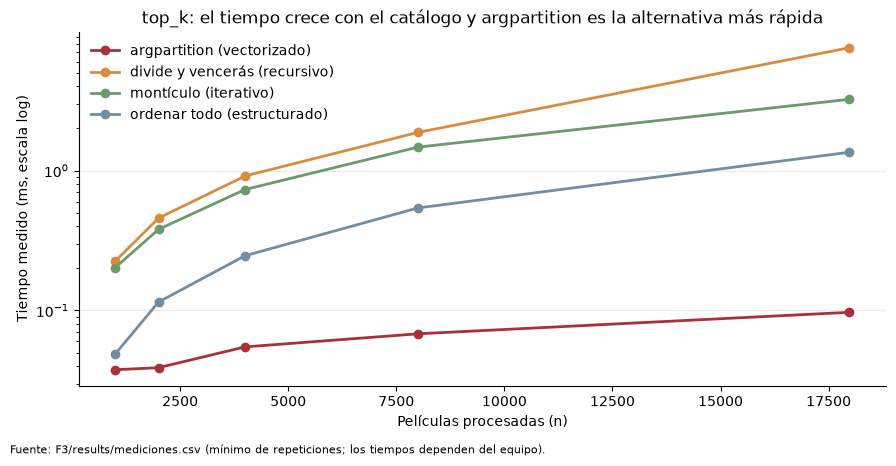

**Decisión respaldada.** Con **17.978 películas**, `argpartition (vectorizado)` tardó **0,097 ms** y `divide y vencerás (recursivo)` **7,54 ms** (**78 veces** más). En el experimento de la sopa de metadatos, por columnas fue **4,86 veces más rápida** que `iterrows`, medido en un solo tamaño (14.382). La elección responde a medición, no a preferencia estilística; la memoria se examina por separado.

In [8]:
# Figura de tendencias: top_k de F3, una serie por algoritmo. top_k y aplanar tienen cinco tamaños; se grafica top_k porque compara cuatro alternativas para elegir las recomendaciones.
tk = med[med['experimento'].eq('top_k')]
tabla_t = tk.pivot(index='n', columns='versión', values='tiempo_s').sort_index()
colores = {'ordenar todo (estructurado)': '#738DA3', 'divide y vencerás (recursivo)': '#D98C3F',
           'montículo (iterativo)': '#6B9A6B', 'argpartition (vectorizado)': '#A93238'}
fig, ax = plt.subplots(figsize=(9, 4.5))
for col in tabla_t:
    ax.plot(tabla_t.index, tabla_t[col]*1000, marker='o', linewidth=2, label=col, color=colores.get(col))
ax.set(title='top_k: el tiempo crece con el catálogo y argpartition es la alternativa más rápida',
       xlabel='Películas procesadas (n)', ylabel='Tiempo medido (ms, escala log)', yscale='log')
ax.grid(axis='y', alpha=.25); ax.legend(frameon=False); ax.spines[['top', 'right']].set_visible(False)
fig.text(0.01, -0.02, 'Fuente: F3/results/mediciones.csv (mínimo de repeticiones; los tiempos dependen del equipo).', fontsize=8)
plt.tight_layout(); plt.show()
ultimo = tabla_t.index.max()
rapida, lenta = tabla_t.loc[ultimo].idxmin(), tabla_t.loc[ultimo].idxmax()
display(Markdown(f"**Decisión respaldada.** Con **{es(ultimo, 0)} películas**, `{rapida}` tardó "
                 f"**{es(tabla_t.loc[ultimo, rapida]*1000, 3)} ms** y `{lenta}` **{es(tabla_t.loc[ultimo, lenta]*1000, 2)} ms** "
                 f"(**{es(tabla_t.loc[ultimo, lenta]/tabla_t.loc[ultimo, rapida], 0)} veces** más). "
                 f"En el experimento de la sopa de metadatos, por columnas fue **{es(t_iter/t_col)} veces más rápida** "
                 f"que `iterrows`, medido en un solo tamaño ({es(n_sopa, 0)}). "
                 "La elección responde a medición, no a preferencia estilística; la memoria se examina por separado."))

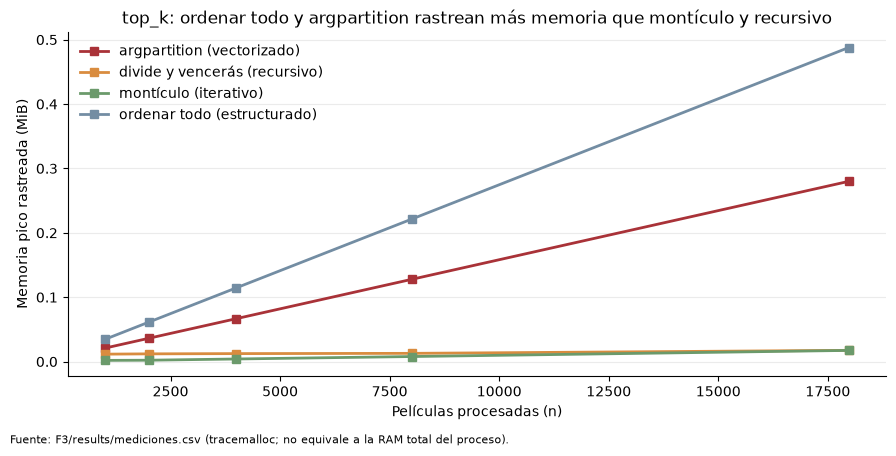

**Compromiso observado.** Con **17.978 películas**, el menor pico fue de `montículo (iterativo)` (**0,017 MiB**) y el mayor de `ordenar todo (estructurado)` (**0,488 MiB**). En la sopa de metadatos, la versión por columnas rastreó **1,24 veces** la memoria de `iterrows()`: más velocidad no implicó menos memoria.

In [9]:
# Figura espacial complementaria: la ganancia temporal no debe ocultar el costo de memoria.
tabla_m = tk.pivot(index='n', columns='versión', values='memoria_pico_MB').sort_index()
fig, ax = plt.subplots(figsize=(9, 4.4))
for col in tabla_m:
    ax.plot(tabla_m.index, tabla_m[col], marker='s', linewidth=2, color=colores.get(col), label=col)
ax.set(title='top_k: ordenar todo y argpartition rastrean más memoria que montículo y recursivo',
       xlabel='Películas procesadas (n)', ylabel='Memoria pico rastreada (MiB)')
ax.grid(axis='y', alpha=.25); ax.legend(frameon=False); ax.spines[['top', 'right']].set_visible(False)
fig.text(0.01, -0.02, 'Fuente: F3/results/mediciones.csv (tracemalloc; no equivale a la RAM total del proceso).', fontsize=8)
plt.tight_layout(); plt.show()
bajo, alto = tabla_m.loc[ultimo].idxmin(), tabla_m.loc[ultimo].idxmax()
display(Markdown(f"**Compromiso observado.** Con **{es(ultimo, 0)} películas**, el menor pico fue de `{bajo}` "
                 f"(**{es(tabla_m.loc[ultimo, bajo], 3)} MiB**) y el mayor de `{alto}` (**{es(tabla_m.loc[ultimo, alto], 3)} MiB**). "
                 f"En la sopa de metadatos, la versión por columnas rastreó **{es(m_col/m_iter)} veces** la memoria de `iterrows()`: "
                 "más velocidad no implicó menos memoria."))

## 5. Asociación no es causalidad

Describimos el catálogo disponible (entrenamiento + prueba, una fila por película), no recalibramos el recomendador. Entre las tres parejas de **promedio de votos**, **número de votos** y **popularidad**, comparamos la correlación de Spearman sobre los mismos registros y seleccionamos la de mayor magnitud. Excluimos puntuaciones derivadas para no presentar como hallazgo una relación inducida por su fórmula.

Repetimos la comparación dentro de inglés y otros idiomas conocidos: el idioma original puede estar relacionado con exposición, audiencia y disponibilidad, y el grupo de otros idiomas es heterogéneo. Mostramos por separado el grupo sin idioma; un grupo pequeño no admite una interpretación estable. Estratificar por idioma no ajusta por año, distribución ni otras fuentes de exposición. Además, la [documentación de TMDB sobre popularidad](https://developer.themoviedb.org/docs/popularity-and-trending) incluye los votos totales entre los factores del indicador. Por tanto, número de votos y popularidad no son mediciones independientes.

In [10]:
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))
from src.f4_puntos_5_7 import (analizar_asociacion, cargar_contrato, controles_tecnicos,
                              figura_asociacion_votos, figura_umbral_votos, persistir, persistir_apoyo)

ent_f4, prueba_f4, dic_f4, parametros_f4, original_f4 = cargar_contrato(RAIZ)
catalogo_f4 = pd.concat([ent_f4, prueba_f4], ignore_index=True)
par_f4, pares_f4, estratos_f4, excluidas_f4 = analizar_asociacion(catalogo_f4)
formato_es = {"n": "{:,.0f}", "rho": "{:.3f}"}
display(*(t.style.format(formato_es, decimal=",", thousands=".").hide(axis="index") for t in (pares_f4, estratos_f4)))
print(f"Registros excluidos de la comparación por faltantes: {es(excluidas_f4, 0)}")

x,y,n,rho
vote_average,vote_count,17.978,"0,198"
vote_average,popularity,17.978,"0,196"
vote_count,popularity,17.978,"0,626"


grupo,n,rho
Catálogo completo,17.978,"0,626"
Idioma inglés,10.615,"0,751"
Otros idiomas conocidos,7.355,"0,378"
Idioma no informado,8,"0,571"


Registros excluidos de la comparación por faltantes: 0


En este extracto, un mayor número de votos **se asocia con** mayor popularidad (ρ = 0,626). La asociación permanece positiva en inglés (ρ = 0,751) y en otros idiomas conocidos (ρ = 0,378), con distinta intensidad. El grupo sin idioma informado (n = 8) se muestra por completitud y no se interpreta. Esto no permite concluir que votar más cause mayor popularidad ni descartar diferencias de exposición. Parte de la asociación puede deberse a la propia construcción del indicador de TMDB, que incorpora los votos totales entre otros factores.

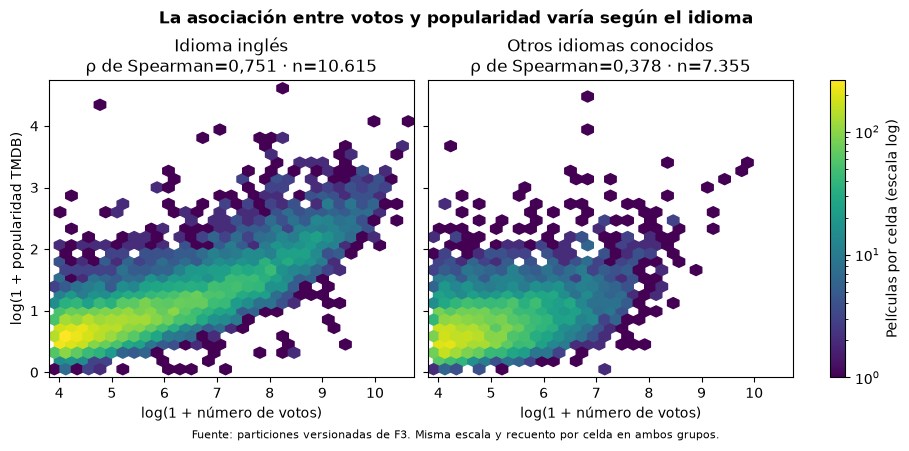

**Lectura de la figura.** Idioma inglés: ρ=0,751 (n=10.615); Otros idiomas conocidos: ρ=0,378 (n=7.355); idioma no informado fuera de la figura: 8. Asociación descriptiva, no causal. Las celdas agrupan películas para evitar la superposición. El coeficiente se calcula por grupo con los datos completos, no sobre una muestra.

In [11]:
rho_f4 = estratos_f4.set_index("grupo")["rho"]
n_sin_idioma = int(estratos_f4.set_index("grupo").loc["Idioma no informado", "n"])
if par_f4 == ("vote_count", "popularity") and rho_f4.iloc[:3].gt(0).all():
    display(Markdown(
        "En este extracto, un mayor número de votos **se asocia con** mayor popularidad "
        f"(ρ = {es(rho_f4['Catálogo completo'], 3)}). La asociación permanece positiva "
        f"en inglés (ρ = {es(rho_f4['Idioma inglés'], 3)}) y en otros idiomas conocidos "
        f"(ρ = {es(rho_f4['Otros idiomas conocidos'], 3)}), con distinta intensidad. "
        f"El grupo sin idioma informado (n = {es(n_sin_idioma, 0)}) se muestra por completitud y no se interpreta. "
        "Esto no permite concluir que votar más cause mayor popularidad ni descartar "
        "diferencias de exposición. Parte de la asociación puede deberse a la propia construcción "
        "del indicador de TMDB, que incorpora los votos totales entre otros factores."
    ))
else:
    display(Markdown(
        f"La asociación de mayor magnitud corresponde a **{par_f4[0]}** y **{par_f4[1]}**. "
        "Revisar la interpretación antes de incorporar esta nueva ejecución al informe."
    ))

fig_asoc_f4, hallazgo_asoc_f4 = figura_asociacion_votos(catalogo_f4)
plt.show()
display(Markdown("**Lectura de la figura.** " + hallazgo_asoc_f4["evidencia"] + " "
                 "Las celdas agrupan películas para evitar la superposición. "
                 "El coeficiente se calcula por grupo con los datos completos, no sobre una muestra."))

## 6. Validación técnica

La tabla comprueba **casos normales** (contrato, tamaños, identificadores y valores contra el CSV original), **casos límite** (ausentes intencionales, valores de prueba fuera del rango aprendido y estratos sin variación) y **excepciones** (archivo ausente o muestra insuficiente). Comparamos por `movie_id` y mantenemos presupuesto y recaudación faltantes como nulos, sin sustituirlos por cero.

Las transformaciones de calidad y popularidad se ajustaron en entrenamiento. Si una observación de prueba cae fuera del intervalo aprendido y la fórmula no especifica recorte, un resultado fuera de [0, 1] es esperable: no se reajustan parámetros ni se recortan las puntuaciones para que el control pase. El parámetro de regularización del Weighted Rating (`m=421`) no es el umbral de 428 votos usado en la evaluación.

**Alcance de la comparación:** la línea aleatoria de F1 es una referencia histórica. El CSV de F3 la muestra al lado de dos métodos evaluados con **3.596 consultas de prueba**, pero no demuestra que la línea F1 se obtuviera con ese mismo conjunto de consultas y candidatos. Las columnas de similitud e híbrido sí comparten el protocolo de F3. La coherencia de género, la coincidencia de idioma y el respaldo de votos son métricas indirectas; ninguna mide satisfacción de usuarios.

,escenario,control,estado,detalle
0,normal,Columnas y orden según el diccionario,OK,16 columnas
1,normal,Particiones versionadas: 14.382 + 3.596,OK,14.382 + 3.596
2,normal,"movie_id no nulo, único, sin cruces y mismo co...",OK,17.978 ids
3,normal,vote_average coincide con el original por movi...,OK,
4,normal,vote_count coincide con el original por movie_id,OK,
5,normal,popularity coincide con el original por movie_id,OK,
6,límite,budget_clean: ceros/nulos conservados como aus...,OK,12.463 valores ausentes
7,límite,revenue_clean: ceros/nulos conservados como au...,OK,11.156 valores ausentes
8,normal,Weighted Rating coincide con la fórmula y los ...,OK,"C=6,3270; m=421"
9,límite,"Con el mínimo de votos observado, Weighted Rat...",OK,226 películas con 50 voto(s)


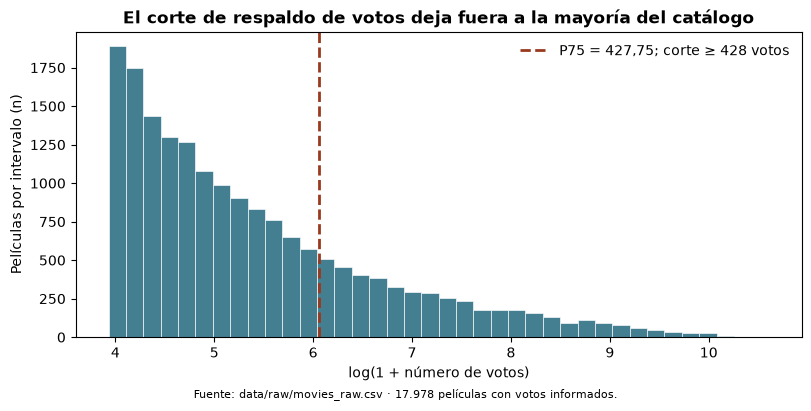

**Lectura de la figura.** P75 del catálogo: 427,75 votos. 4.495 de 17.978 películas (25,0 %) alcanzan al menos 428 votos. No es el parámetro m del Weighted Rating, estimado con entrenamiento. El logaritmo solo cambia la escala visual. El umbral no mide satisfacción.

In [12]:
controles_f4 = controles_tecnicos(ent_f4, prueba_f4, dic_f4, parametros_f4, original_f4)
display(controles_f4)
assert controles_f4["estado"].eq("OK").all(), "Hay controles de Fase 4 que no pasaron."

fig_umbral_f4, hallazgo_umbral_f4 = figura_umbral_votos(original_f4)
plt.show()
display(Markdown("**Lectura de la figura.** " + hallazgo_umbral_f4["evidencia"] + " "
                 "El logaritmo solo cambia la escala visual. El umbral no mide satisfacción."))

## 7. Persistencia

Se guardan las **dos figuras complementarias** de los puntos 5 y 6, con sus hallazgos, en `F4/figuras/apoyo_puntos_5_7/`. No representan las tres figuras principales de la entrega.

Por separado, se exportan las **tres figuras principales que el equipo seleccione** a `F4/figuras/` (PNG, 200 ppp). Para que informe y guion citen la misma evidencia, `docs/hallazgos_f4.csv` guarda exactamente una fila por figura, acompañada por los controles y los metadatos de ejecución.

En las celdas que generen las tres figuras definitivas, registrar el objeto `Figure` por su identificador y el hallazgo que lo acompaña. En el primer registro, iniciar `figuras_f4 = {}` y `hallazgos_f4 = []`; después incorporar cada figura como `figuras_f4["figura_nombre"] = fig` y su fila como `hallazgos_f4.append({"figura": "figura_nombre", "hallazgo": titulo, "evidencia": cifras_y_limites})`. Los identificadores deben coincidir. Si esas figuras aún no se integraron, esta celda informa el pendiente sin publicar archivos de ejemplo como evidencia.

In [13]:
rutas_apoyo_f4 = persistir_apoyo(RAIZ, [(fig_asoc_f4, hallazgo_asoc_f4),
                                        (fig_umbral_f4, hallazgo_umbral_f4)], controles_f4)
print("Apoyo visual de los puntos 5–7:")
for ruta_apoyo_f4 in rutas_apoyo_f4:
    print(ruta_apoyo_f4)

registro_figuras_f4 = globals().get("figuras_f4", {})
registro_hallazgos_f4 = globals().get("hallazgos_f4", [])
if not registro_figuras_f4 and not registro_hallazgos_f4:
    print("Exportación pendiente: registrar las tres figuras principales y sus hallazgos.")
else:
    tabla_hallazgos_f4 = pd.DataFrame(registro_hallazgos_f4)
    rutas_f4 = persistir(RAIZ, registro_figuras_f4, tabla_hallazgos_f4, controles_f4, parametros_f4)
    display(tabla_hallazgos_f4)
    for ruta_f4 in rutas_f4.values():
        print(ruta_f4)

Apoyo visual de los puntos 5–7:
F4/figuras/apoyo_puntos_5_7/p05_votos_popularidad.png
F4/figuras/apoyo_puntos_5_7/p06_umbral_respaldo_votos.png
F4/figuras/apoyo_puntos_5_7/hallazgos_apoyo.csv
Exportación pendiente: registrar las tres figuras principales y sus hallazgos.


### Preparación del capítulo 8: el recomendador oficial de F3

El capítulo 8 evalúa con las mismas piezas que F3, sin reajustar nada: catálogo = entrenamiento + prueba (17.978 películas), vocabulario aprendido en entrenamiento, consultas = las 3.596 películas de prueba, pesos de `parametros_f3.json` y umbral de votos = P75 del CSV original (427,75; en la práctica, ≥ 428 votos). Género, idioma y votos se toman del CSV original, unidos por `movie_id`.

Antes de usar estas piezas, se recalculan **solo similitud** e **híbrido** con las mismas funciones que usará el capítulo 8 y se comparan con `F3/results/evaluacion_recomendador.csv`. Si no coinciden, el cuaderno se detiene: así, el capítulo 8 queda conectado con el módulo de recomendación de F3.

In [14]:
from src.f4_puntos_5_7 import preparar_evaluacion, verificar_contra_f3

prep_f4 = preparar_evaluacion(RAIZ)
vis, test_f3 = prep_f4["vis"], prep_f4["test_f3"]
GEN, IDI, VOTOS, CALIDAD = prep_f4["GEN"], prep_f4["IDI"], prep_f4["VOTOS"], prep_f4["CALIDAD"]
P75, TOP_K, N_CATALOGO = prep_f4["P75"], prep_f4["TOP_K"], prep_f4["N_CATALOGO"]
CONSULTAS_TEST, METRICAS = prep_f4["CONSULTAS_TEST"], prep_f4["METRICAS"]
puntajes_consulta, top_k_por_score = prep_f4["puntajes_consulta"], prep_f4["top_k_por_score"]

print(prep_f4["recomendador"])
print(f"Catálogo: {es(N_CATALOGO, 0)} películas | consultas de prueba: {es(len(CONSULTAS_TEST), 0)} | "
      f"P75 de votos: {es(P75, 2)}")
verificacion_f3 = verificar_contra_f3(prep_f4, RAIZ)
display(verificacion_f3.style.format({"F3 (CSV)": "{:.2%}", "F4 (reproducido)": "{:.2%}"}, decimal=",")
        .hide(axis="index"))
assert verificacion_f3["coincide"].all(), "F4 no reproduce la evaluación de F3; revisar antes del capítulo 8."

RecomendadorHibrido(similitud=0.5, calidad=0.5, popularidad=0, n=10, ajustado)
Catálogo: 17.978 películas | consultas de prueba: 3.596 | P75 de votos: 427,75


estrategia,criterio,F3 (CSV),F4 (reproducido),coincide
Solo similitud,Coherencia de género,"99,56%","99,56%",True
Solo similitud,Coherencia de idioma,"95,26%","95,26%",True
Solo similitud,Respaldo de votos (>= 428),"15,57%","15,57%",True
Híbrido (pesos elegidos),Coherencia de género,"98,97%","98,97%",True
Híbrido (pesos elegidos),Coherencia de idioma,"81,35%","81,35%",True
Híbrido (pesos elegidos),Respaldo de votos (>= 428),"80,03%","80,03%",True


## Capítulo 8 · Evaluar sin cambiar la pregunta de F1

**Problema.** Un buen resultado no se define por elegir diez películas visualmente atractivas. La prueba final debe responder con las mismas tres medidas de F1 para **todas las consultas de prueba de F3**, sin usar la evaluación para seleccionar pesos. También hay que comparar contra una estrategia simple que no utiliza el contenido: diez películas elegidas al azar para cada consulta, excluyendo la propia película.

**Decisión.** Construir una tabla de resultados con diez filas por consulta y por estrategia. Conservamos la relación consulta–recomendación para calcular promedios por consulta, identificar diferencias lingüísticas, examinar casos individuales y estimar incertidumbre mediante bootstrap. Añadimos **solo similitud** como comparación diagnóstica; no sustituye a la línea base aleatoria indicada en F1.

**Alcance:** el protocolo queda definido de manera transparente dentro de F4. Su equivalencia exacta con algún módulo de recomendación de F3 debe verificarse con el código oficial si ese módulo existe.

In [15]:
RNG_AZAR=np.random.default_rng(SEMILLA+24)
registros=[]
for ii,q0 in enumerate(CONSULTAS_TEST):
    q=int(q0)
    simil=puntajes_consulta(q)
    indices_h=top_k_por_score(.5*simil+.5*CALIDAD,q)
    indices_s=top_k_por_score(simil,q)
    # Aleatorio: 10 sin reemplazo, sin incluir la consulta.
    aleatorios=RNG_AZAR.choice(N_CATALOGO-1,size=TOP_K,replace=False)
    aleatorios=np.where(aleatorios>=q,aleatorios+1,aleatorios)
    for metodo,indices in [('Híbrido F4',indices_h),('Solo similitud',indices_s),('Aleatorio',aleatorios)]:
        for puesto,r0 in enumerate(indices,start=1):
            r=int(r0)
            registros.append({'consulta_idx':q,'consulta_id':vis.at[q,'movie_id'],
                'recomendado_idx':r,'recomendado_id':vis.at[r,'movie_id'],
                'método':metodo,'puesto':puesto,'idioma_consulta':IDI[q],
                'genero_compartido':bool(GEN[q]&GEN[r]),
                'idioma_coincidente':bool(IDI[q]) and IDI[q]==IDI[r],
                'votos_p75':bool(np.isfinite(VOTOS[r]) and VOTOS[r]>=P75),
                'votos_recomendado':float(VOTOS[r]) if np.isfinite(VOTOS[r]) else np.nan})
res=pd.DataFrame.from_records(registros)
N_CONSULTAS=len(CONSULTAS_TEST)
assert N_CONSULTAS==3596
assert len(res)==N_CONSULTAS*TOP_K*3
assert res.groupby(['consulta_idx','método']).size().eq(TOP_K).all()
assert not res.duplicated(['consulta_idx','método','recomendado_idx']).any()
assert (res.consulta_idx!=res.recomendado_idx).all()
assert res.consulta_idx.nunique()==3596
assert set(res.consulta_id)==set(test_f3.movie_id)
print('Evaluadas',N_CONSULTAS,'consultas ×',TOP_K,'recomendaciones × 3 estrategias =',len(res),'filas.')
print('Los resultados provienen del conjunto test F3; los datos de F2 solo alimentan la comparación.')

Evaluadas 3596 consultas × 10 recomendaciones × 3 estrategias = 107880 filas.
Los resultados provienen del conjunto test F3; los datos de F2 solo alimentan la comparación.


### Interpretación de la ejecución: lo que realmente se ha medido

Cada fila de `res` vincula una película consultada con una recomendación y registra tres hechos verificables: comparte algún género, tiene el mismo idioma original y alcanza el percentil 75 de votos. **No contiene valoraciones de usuarios sobre las recomendaciones**. La unidad de observación para describir una lista es cada pareja; sin embargo, **la unidad estadística para construir intervalos de confianza es la consulta**, porque las diez sugerencias de una misma película están relacionadas.

Conservar esta tabla es una decisión importante del equipo: permite pasar de una tasa general a una explicación más fina de por qué el sistema funciona para algunos grupos y no para otros.

In [16]:
# Comparación emparejada por consulta y bootstrap de consultas (no de recomendaciones).
por_consulta=(res.groupby(['consulta_idx','método'],sort=False)[list(METRICAS.values())]
               .mean().reset_index())
# Ordénese en el orden de las consultas F3.
BOOT_N=1500
RNG_BOOT=np.random.default_rng(SEMILLA+2026)
filas=[]
for nombre,col in METRICAS.items():
    piv=por_consulta.pivot(index='consulta_idx',columns='método',values=col).loc[CONSULTAS_TEST]
    assert not piv.isna().any().any()
    arr_h=piv['Híbrido F4'].to_numpy();arr_a=piv['Aleatorio'].to_numpy()
    # Cada remuestreo selecciona consultas completas con reemplazo.
    bootstrap_h=[];bootstrap_a=[];bootstrap_diff=[]
    for b in range(BOOT_N):
        ii=RNG_BOOT.integers(0,len(piv),size=len(piv))
        h=float(arr_h[ii].mean());a=float(arr_a[ii].mean())
        bootstrap_h.append(h);bootstrap_a.append(a);bootstrap_diff.append(h-a)
    ref=float(criterios.set_index('objetivo').loc[nombre,'referencia_readme'])
    filas.append({'criterio':nombre,'columna':col,
       'hibrido_pct':100*arr_h.mean(),'aleatorio_pct':100*arr_a.mean(),
       'diferencia_pp':100*(arr_h-arr_a).mean(),'referencia_f1_pct':100*ref,
       'hibrido_ic_inf':100*np.percentile(bootstrap_h,2.5),'hibrido_ic_sup':100*np.percentile(bootstrap_h,97.5),
       'azar_ic_inf':100*np.percentile(bootstrap_a,2.5),'azar_ic_sup':100*np.percentile(bootstrap_a,97.5),
       'dif_ic_inf':100*np.percentile(bootstrap_diff,2.5),'dif_ic_sup':100*np.percentile(bootstrap_diff,97.5),
       'n_consultas':len(piv)})
comparativa=pd.DataFrame(filas)
display(comparativa.round(2))
print('IC bootstrap percentil al 95 %; 1500 remuestreos, unidad = consulta de F3.')

,criterio,columna,hibrido_pct,aleatorio_pct,diferencia_pp,referencia_f1_pct,hibrido_ic_inf,hibrido_ic_sup,azar_ic_inf,azar_ic_sup,dif_ic_inf,dif_ic_sup,n_consultas
0,Género compartido,genero_compartido,98.97,42.63,56.34,41.8,98.76,99.15,41.87,43.40,55.60,57.11,3596
1,Idioma coincidente,idioma_coincidente,81.35,36.67,44.68,36.6,80.37,82.30,35.74,37.66,43.85,45.55,3596
2,Votos sobre P75,votos_p75,80.03,24.98,55.04,25.0,79.22,80.85,24.56,25.43,54.13,55.94,3596


IC bootstrap percentil al 95 %; 1500 remuestreos, unidad = consulta de F3.


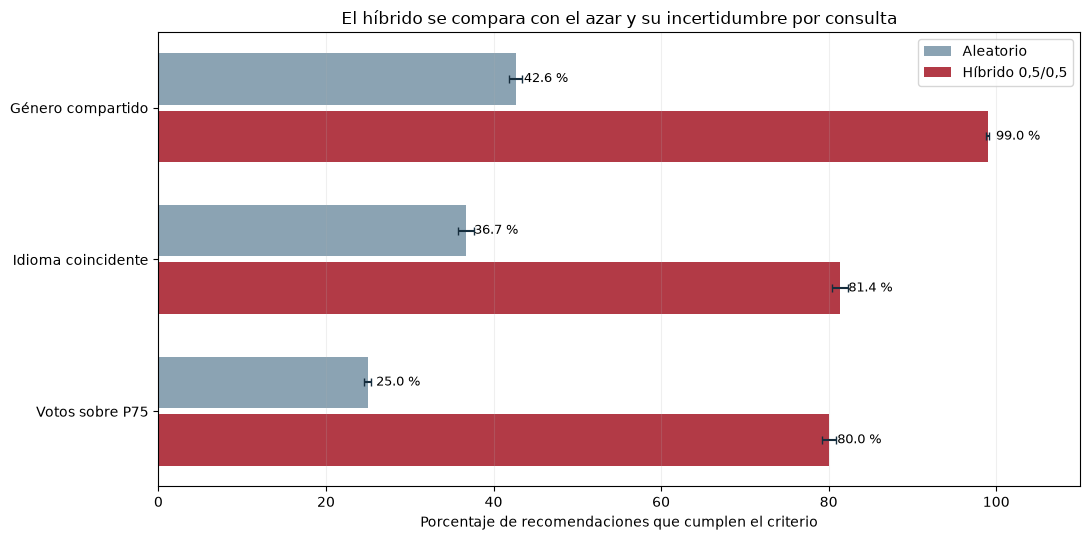

**Género compartido.** El equipo obtuvo **98.97 %** (IC 95 %: 98.76–99.15) frente a **42.63 %** al azar. La diferencia fue **+56.34 pp** (IC 95 % diferencia: +55.60 a +57.11 pp; intervalo de mejora positivo).

**Idioma coincidente.** El equipo obtuvo **81.35 %** (IC 95 %: 80.37–82.30) frente a **36.67 %** al azar. La diferencia fue **+44.68 pp** (IC 95 % diferencia: +43.85 a +45.55 pp; intervalo de mejora positivo).

**Votos sobre P75.** El equipo obtuvo **80.03 %** (IC 95 %: 79.22–80.85) frente a **24.98 %** al azar. La diferencia fue **+55.04 pp** (IC 95 % diferencia: +54.13 a +55.94 pp; intervalo de mejora positivo).

In [17]:
# Figura central con errores IC 95 % por consulta y referencia F1.
fig,ax=plt.subplots(figsize=(11,5.5))
y=np.arange(len(comparativa));delta=.19
for metodo,key,inf,sup,color,dy in [
    ('Aleatorio','aleatorio_pct','azar_ic_inf','azar_ic_sup','#8BA3B3',-delta),
    ('Híbrido 0,5/0,5','hibrido_pct','hibrido_ic_inf','hibrido_ic_sup','#B23A46',delta)]:
    x=comparativa[key].to_numpy()
    errs=np.vstack([x-comparativa[inf].to_numpy(),comparativa[sup].to_numpy()-x])
    ax.barh(y+dy,x,height=.34,color=color,label=metodo)
    ax.errorbar(x,y+dy,xerr=errs,fmt='none',ecolor='#162D3D',capsize=3,lw=1.5)
    for j,v in enumerate(x):ax.text(v+1,y[j]+dy,f'{v:.1f} %',va='center',fontsize=9)
ax.set_yticks(y,comparativa.criterio);ax.invert_yaxis()
ax.set_xlim(0,110);ax.set_xlabel('Porcentaje de recomendaciones que cumplen el criterio')
ax.set_title('El híbrido se compara con el azar y su incertidumbre por consulta')
ax.grid(axis='x',alpha=.2);ax.legend()
plt.tight_layout();plt.show()
for _,r in comparativa.iterrows():
    estado='intervalo de mejora positivo' if r.dif_ic_inf>0 else 'intervalo incluye cero o valores negativos'
    display(Markdown(f"**{r.criterio}.** El equipo obtuvo **{r.hibrido_pct:.2f} %** "
       f"(IC 95 %: {r.hibrido_ic_inf:.2f}–{r.hibrido_ic_sup:.2f}) frente a "
       f"**{r.aleatorio_pct:.2f} %** al azar. La diferencia fue **{r.diferencia_pp:+.2f} pp** "
       f"(IC 95 % diferencia: {r.dif_ic_inf:+.2f} a {r.dif_ic_sup:+.2f} pp; {estado})."))

## Capítulo 9 · El promedio global plantea una nueva pregunta: ¿a qué idiomas beneficia?

**Problema detectado en la retroalimentación.** Se comunicó una diferencia importante de coherencia lingüística: 98,9 % en consultas en inglés y 56,5 % en otros idiomas. **Estos valores constituyen una observación docente que debe contrastarse**, no cifras que este cuaderno imponga a su propia ejecución. El Weighted Rating favorece películas muy votadas, frecuentemente en inglés, lo que puede afectar recomendaciones en otros idiomas.

**Decisión.** Desagregar los **tres criterios**, no solo idioma, por idioma original de consulta. Registrar siempre el tamaño de cada grupo, porque un 100 % sobre unas pocas películas puede ser engañoso. La tabla y el gráfico siguientes permiten identificar en qué idiomas el híbrido gana respaldo de votos y a cambio de cuánta coherencia temática o lingüística.

**Interpretación prudente.** Si aparece una brecha, se hablará de desigualdad descriptiva observada en este catálogo, no de causalidad demostrada ni de satisfacción de usuarios.

,idioma_consulta,método,genero_compartido,idioma_coincidente,votos_p75,n_consultas
0,de,Aleatorio,40.00,1.88,25.65,69
1,de,Híbrido F4,98.26,38.55,71.45,69
2,de,Solo similitud,98.41,86.96,8.99,69
3,en,Aleatorio,40.70,59.38,25.05,2109
4,en,Híbrido F4,99.20,98.85,84.49,2109
5,en,Solo similitud,99.97,99.97,18.78,2109
6,es,Aleatorio,45.11,5.56,25.67,178
7,es,Híbrido F4,98.93,75.62,58.26,178
8,es,Solo similitud,99.04,97.19,8.20,178
9,fr,Aleatorio,45.11,9.50,24.13,378


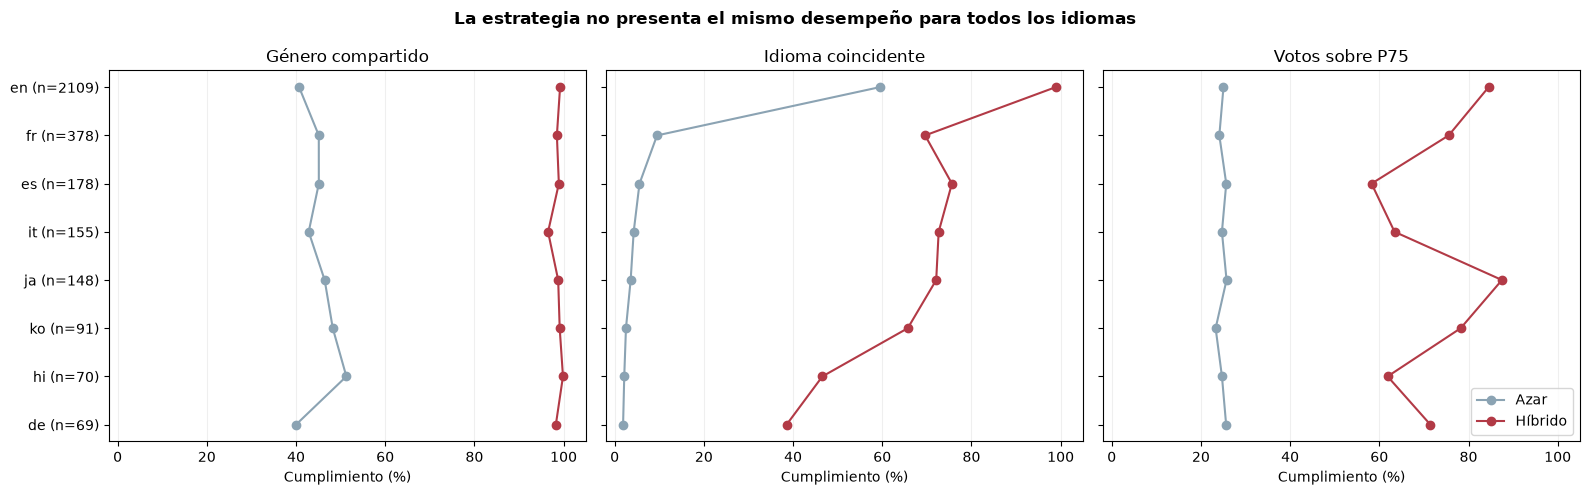

,genero_compartido,idioma_coincidente,votos_p75,n_consultas
grupo_idioma,,,,
Inglés (en),99.20,98.85,84.49,2109
Otros idiomas,98.64,56.53,73.70,1487


Brecha idioma (inglés - otros): 42.32 pp


In [18]:
# Tres criterios por idioma y estrategia, con denominadores en consultas.
idiomas_n=(por_consulta.loc[por_consulta.método=='Híbrido F4',['consulta_idx']]
    .merge(res[['consulta_idx','idioma_consulta']].drop_duplicates(),on='consulta_idx',validate='one_to_one')
    .idioma_consulta.value_counts())
idiomas_top=idiomas_n.head(8).index.tolist()
lang=(res[res.idioma_consulta.isin(idiomas_top)]
  .groupby(['idioma_consulta','método'])[list(METRICAS.values())].mean()*100).reset_index()
lang['n_consultas']=lang.idioma_consulta.map(idiomas_n)
display(lang.round(2))
fig,axs=plt.subplots(1,3,figsize=(16,5),sharey=True)
for ax,(nombre,col) in zip(axs,METRICAS.items()):
    mat=lang.pivot(index='idioma_consulta',columns='método',values=col).reindex(idiomas_top)
    posiciones=np.arange(len(mat))
    ax.plot(mat['Aleatorio'],posiciones,marker='o',color='#8BA3B3',label='Azar')
    ax.plot(mat['Híbrido F4'],posiciones,marker='o',color='#B23A46',label='Híbrido')
    ax.set(xlim=(-2,105),xlabel='Cumplimiento (%)',title=nombre)
    ax.grid(axis='x',alpha=.2)
    ax.set_yticks(posiciones,[f'{idi} (n={int(idiomas_n[idi])})' for idi in mat.index])
axs[0].invert_yaxis();axs[-1].legend(loc='lower right')
fig.suptitle('La estrategia no presenta el mismo desempeño para todos los idiomas',fontweight='bold')
plt.tight_layout();plt.show()
# Comparación inglés frente a restantes, calculada desde las mismas 3.596 consultas.
res_lang=res[res.método=='Híbrido F4'].copy()
res_lang['grupo_idioma']=np.where(res_lang.idioma_consulta=='en','Inglés (en)','Otros idiomas')
por_grupo=res_lang.groupby('grupo_idioma')[list(METRICAS.values())].mean()*100
por_grupo['n_consultas']=res_lang.groupby('grupo_idioma').consulta_idx.nunique()
display(por_grupo.round(2))
#if {"Inglés (en)", "Otros idiomas"}.issubset(por_grupo.index):
#    tasa_ingles: float = float(por_grupo.at["Inglés (en)", "idioma_coincidente"])
#    tasa_otros: float = float(por_grupo.at["Otros idiomas", "idioma_coincidente"])
#    brecha: float = tasa_ingles - tasa_otros
#    print(f"Brecha de idioma (inglés frente a otros): {brecha:.2f} pp")
if {'Inglés (en)','Otros idiomas'}<=set(por_grupo.index):
    print('Brecha idioma (inglés - otros):',round(por_grupo.loc['Inglés (en)','idioma_coincidente']-por_grupo.loc['Otros idiomas','idioma_coincidente'],2),'pp')
    

### Lectura crítica de la brecha lingüística

La desagregación aporta una explicación que el promedio total no permite: **el mismo sistema puede conservar el idioma para una consulta en inglés y fallar en una consulta de otra lengua**. Por eso el equipo debe informar los tamaños de los subgrupos junto con las tasas y conectar esta asimetría con la ponderación de calidad, sin atribuirla exclusivamente a esa causa sin pruebas adicionales.

Una extensión posible sería variar el peso de calidad según el idioma de la consulta. **No se confunde con el modelo principal**: tendría que evaluarse con las mismas consultas, un criterio fijado por anticipado y compararse en una tabla separada. Esta versión conserva intacta la evaluación principal 0,50/0,50.

## Capítulo 10 · Otra consecuencia de premiar la calidad: ¿se repiten siempre las mismas películas?

**Problema.** Un sistema puede registrar buenas tasas de coincidencia y, aun así, concentrar casi todas sus recomendaciones en unos pocos títulos populares. El promedio de los tres criterios no detecta este efecto.

**Decisión.** Medir cobertura y concentración de las apariciones sobre las 3.596 consultas. Cobertura es el porcentaje del catálogo que aparece al menos una vez; concentración Top-10 es el porcentaje de todas las recomendaciones acumulado por los diez títulos más repetidos. También se informa una medida de concentración cuadrática (HHI) para comparar métodos.

La diversidad que se examina es **diversidad de exposición**, no diversidad narrativa o satisfacción.

método,cobertura_catalogo_pct,peliculas_distintas,top10_apariciones_pct,HHI_exposicion,apariciones_totales
Aleatorio,"86,49",15.550,"0,23","0,0001",35.960
Híbrido F4,"20,99",3.773,"16,52","0,0055",35.960
Solo similitud,"49,25",8.854,"3,60","0,0007",35.960


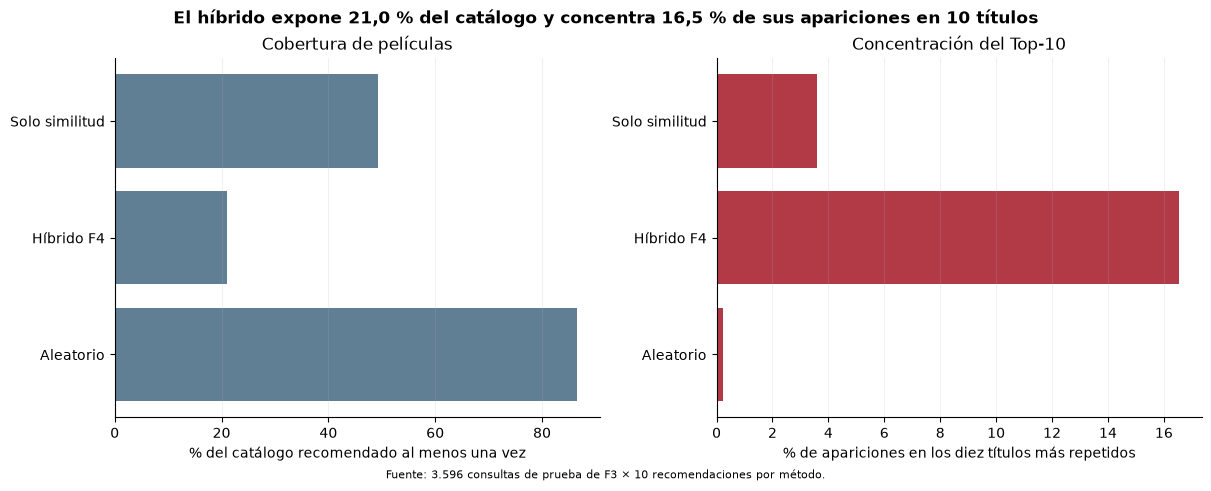

Aleatorio: 86,49% del catálogo expuesto y 0,23% de apariciones concentradas en el Top-10.
Híbrido F4: 20,99% del catálogo expuesto y 16,52% de apariciones concentradas en el Top-10.
Solo similitud: 49,25% del catálogo expuesto y 3,60% de apariciones concentradas en el Top-10.


In [19]:
def es_signo(x, d=2):
    """Como es(), con signo explícito."""
    return ('+' if x >= 0 else '') + es(x, d)

diversidad=[]
for metodo,g in res.groupby('método'):
    frec=g.recomendado_idx.value_counts()
    share=frec/len(g)
    diversidad.append({'método':metodo,'cobertura_catalogo_pct':100*frec.size/N_CATALOGO,
        'peliculas_distintas':int(frec.size),'top10_apariciones_pct':100*frec.nlargest(10).sum()/len(g),
        'HHI_exposicion':float((share**2).sum()),'apariciones_totales':len(g)})
diversidad=pd.DataFrame(diversidad).sort_values('método')
display(diversidad.style.format({'cobertura_catalogo_pct': '{:.2f}', 'top10_apariciones_pct': '{:.2f}', 'HHI_exposicion': '{:.4f}',
                               'peliculas_distintas': '{:,.0f}', 'apariciones_totales': '{:,.0f}'}, decimal=',', thousands='.').hide(axis='index'))
fig,axs=plt.subplots(1,2,figsize=(12,4.8),layout='constrained')
axs[0].barh(diversidad.método,diversidad.cobertura_catalogo_pct,color='#607F95')
axs[0].set(xlabel='% del catálogo recomendado al menos una vez',title='Cobertura de películas')
axs[1].barh(diversidad.método,diversidad.top10_apariciones_pct,color='#B23A46')
axs[1].set(xlabel='% de apariciones en los diez títulos más repetidos',title='Concentración del Top-10')
for ax in axs:ax.grid(axis='x',alpha=.18);ax.spines[['top','right']].set_visible(False)
h=diversidad.set_index('método').loc['Híbrido F4']
fig.suptitle(f"El híbrido expone {es(h.cobertura_catalogo_pct,1)} % del catálogo y concentra {es(h.top10_apariciones_pct,1)} % de sus apariciones en 10 títulos",fontweight='bold')
fig.supxlabel(f"Fuente: {es(N_CONSULTAS,0)} consultas de prueba de F3 × {TOP_K} recomendaciones por método.",fontsize=8)
plt.show()
for _,r in diversidad.iterrows():
    print(f"{r['método']}: {es(r.cobertura_catalogo_pct,2)}% del catálogo expuesto "
          f"y {es(r.top10_apariciones_pct,2)}% de apariciones concentradas en el Top-10.")

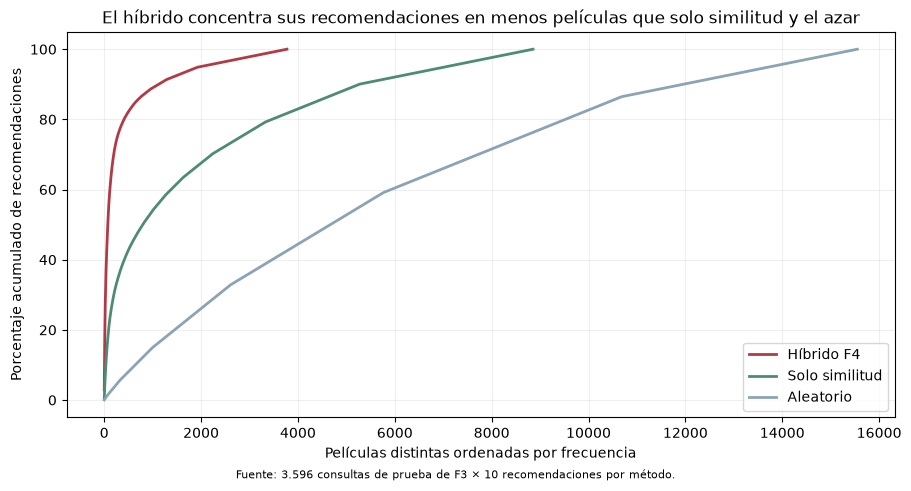

In [20]:
# Curva acumulada de exposición: qué fracción de sugerencias reúnen los títulos más repetidos.
fig,ax=plt.subplots(figsize=(9,4.8),layout='constrained')
for metodo,color in [('Híbrido F4','#B23A46'),('Solo similitud','#4E8C71'),('Aleatorio','#8BA3B3')]:
    frec=res.loc[res.método==metodo,'recomendado_idx'].value_counts().sort_values(ascending=False)
    acum=frec.cumsum()/frec.sum()*100
    ax.plot(np.arange(1,len(acum)+1),acum,label=metodo,color=color,lw=2)
ax.set(xlabel='Películas distintas ordenadas por frecuencia',ylabel='Porcentaje acumulado de recomendaciones',
       title='El híbrido concentra sus recomendaciones en menos películas que solo similitud y el azar')
ax.grid(alpha=.2);ax.legend()
fig.supxlabel(f"Fuente: {es(N_CONSULTAS,0)} consultas de prueba de F3 × {TOP_K} recomendaciones por método.",fontsize=8)
plt.show()

### Interpretación: cobertura y coherencia son objetivos diferentes

Los gráficos permiten distinguir dos preguntas que en F1 podían parecer equivalentes: *¿las recomendaciones son coherentes con la película consultada?* y *¿el sistema da visibilidad a una parte amplia del catálogo?* La primera se responde con género, idioma y votos; la segunda, con cobertura y concentración.

Si el híbrido mejora el respaldo de votos pero reduce cobertura, el equipo puede describir ese compromiso sin cambiar la definición de F1. Esta nueva medición **completa** la interpretación: muestra una limitación operativa del algoritmo y ayuda a decidir qué extensiones merecen exploración posterior.

## Capítulo 11 · Pasar del porcentaje a películas concretas

Los promedios son necesarios, pero no muestran lo que experimentaría alguien que consulta un título específico. La retroalimentación pide examinar *Parasite* y otros casos: una consulta en inglés, una en otro idioma con buen desempeño y una donde falle.

**Decisión.** Elegir los casos de manera reproducible desde las consultas de prueba F3: *Parasite* se incluye si está en ese conjunto; para los demás se seleccionan consultas que satisfagan criterios explícitos de acierto o fallo. Cada caso compara **solo similitud** frente al **híbrido 0,50/0,50**. Si *Parasite* no está en test, se ilustra por separado sin sumarlo a las 3.596 consultas ni alterar las métricas oficiales.

In [21]:
# Elección de casos sin cambiar los resultados del test; la regla se explica y registra.
por_h=(por_consulta[por_consulta.método=='Híbrido F4']
       .set_index('consulta_idx').join(vis[['title','original_language']].rename(columns={'title':'titulo_consulta'})))
por_h['indice_consulta']=por_h.index
# Solo se consideran consultas del conjunto test al seleccionar ejemplos de acierto/fallo.
parasite=vis.index[vis.title.fillna('').astype(str).str.casefold().str.strip()=='parasite'].tolist()
casos=[]
if parasite:
    q=int(parasite[0]);casos.append(('Parasite (caso solicitado)',q))

def elegir_caso(condicion,excluir):
    elegibles=por_h.loc[condicion & ~por_h.index.isin(excluir)]
    return int(elegibles.sort_index().index[0]) if not elegibles.empty else None

usados=[q for _,q in casos]
en=elegir_caso((por_h.original_language=='en') & (por_h.genero_compartido>=.8) & (por_h.idioma_coincidente>=.8),usados)
if en is not None:casos.append(('Inglés: coherencia alta',en));usados.append(en)
no_en=elegir_caso((por_h.original_language!='en') & (por_h.idioma_coincidente>=.8),usados)
if no_en is not None:casos.append(('Otro idioma: acierto',no_en));usados.append(no_en)
fallo=elegir_caso((por_h.original_language!='en') & (por_h.idioma_coincidente<=.5),usados)
if fallo is not None:casos.append(('Otro idioma: fallo lingüístico',fallo));usados.append(fallo)
print('Casos seleccionados (sin modificar las consultas del test):')
for etiqueta,q in casos:
    print('-',etiqueta,':',vis.at[q,'title'],'| idioma:',IDI[q], '| en test:',q in set(CONSULTAS_TEST))
if not casos:print('No se hallaron casos para los criterios indicados.')

Casos seleccionados (sin modificar las consultas del test):
- Parasite (caso solicitado) : Parasite | idioma: ko | en test: True
- Inglés: coherencia alta : Our Brand Is Crisis | idioma: en | en test: True
- Otro idioma: acierto : Fragtime | idioma: ja | en test: True
- Otro idioma: fallo lingüístico : Two Lives | idioma: de | en test: True


In [22]:
# Tabla interpretable de top-10 por caso, en formato lado a lado.
def recomendaciones_consulta(q, metodo):
    """Top-k del recomendador de F3 para una película fuera del test (solo ilustrativo)."""
    p, s_cos = prep_f4['PESOS'], puntajes_consulta(q)
    if metodo == 'Solo similitud':
        return top_k_por_score(s_cos, q)
    return top_k_por_score(p['similitud']*s_cos + p['calidad']*CALIDAD + p['popularidad']*prep_f4['POPULARIDAD'], q)

for etiqueta,q in casos:
    if q in set(CONSULTAS_TEST):
        g=res[(res.consulta_idx==q)&(res.método.isin(['Solo similitud','Híbrido F4']))].copy()
        g['pelicula_recomendada']=g.recomendado_idx.map(vis['title'])
        g['idioma_recomendado']=g.recomendado_idx.map(vis['original_language'])
        g['votos']=g['votos_recomendado']
    else:
        # Ejemplo ilustrativo adicional, SIN incorporar sus filas a res ni al test.
        filas_caso=[]
        for metodo in ['Solo similitud','Híbrido F4']:
            ix=recomendaciones_consulta(q,metodo=metodo)
            for pos,r in enumerate(ix,1):
                filas_caso.append({'método':metodo,'puesto':pos,'pelicula_recomendada':vis.at[int(r),'title'],
                    'idioma_recomendado':IDI[int(r)],'votos':VOTOS[int(r)],
                    'genero_compartido':bool(GEN[q]&GEN[int(r)]),
                    'idioma_coincidente':bool(IDI[q]) and IDI[q]==IDI[int(r)]})
        g=pd.DataFrame(filas_caso)
    display(Markdown(f"### {etiqueta}: **{vis.at[q,'title']}** (idioma: `{IDI[q]}`)"))
    pivot=g[['puesto','método','pelicula_recomendada','idioma_recomendado','votos',
             'genero_compartido','idioma_coincidente']].sort_values(['puesto','método'])
    display(pivot)
    tasas=g.groupby('método')[['genero_compartido','idioma_coincidente']].mean()*100
    display(tasas.round(1))
    if 'Híbrido F4' in tasas.index and 'Solo similitud' in tasas.index:
        d=tasas.loc['Híbrido F4']-tasas.loc['Solo similitud']
        print(f"Lectura del Grupo 4: el híbrido cambió la coincidencia de género {es_signo(d['genero_compartido'],1)} pp "
              f"y la de idioma {es_signo(d['idioma_coincidente'],1)} pp respecto de solo similitud.")

### Parasite (caso solicitado): **Parasite** (idioma: `ko`)

,puesto,método,pelicula_recomendada,idioma_recomendado,votos,genero_compartido,idioma_coincidente
3330,1,Híbrido F4,The Handmaiden,ko,4393.0,True,True
3340,1,Solo similitud,Sunny,ko,193.0,True,True
3331,2,Híbrido F4,Wild Tales,es,3791.0,True,False
3341,2,Solo similitud,Vanishing Time: A Boy Who Returned,ko,185.0,True,True
3332,3,Híbrido F4,The Intouchables,fr,18584.0,True,False
3342,3,Solo similitud,Yourself and Yours,ko,57.0,True,True
3333,4,Híbrido F4,Whiplash,en,16800.0,True,False
3343,4,Solo similitud,26 Years,ko,74.0,True,True
3334,5,Híbrido F4,Miracle in Cell No. 7,ko,498.0,True,True
3344,5,Solo similitud,The Devil Has a Name,en,62.0,True,False


,genero_compartido,idioma_coincidente
método,,
Híbrido F4,100.0,30.0
Solo similitud,100.0,90.0


Lectura del Grupo 4: el híbrido cambió la coincidencia de género +0,0 pp y la de idioma -60,0 pp respecto de solo similitud.


### Inglés: coherencia alta: **Our Brand Is Crisis** (idioma: `en`)

,puesto,método,pelicula_recomendada,idioma_recomendado,votos,genero_compartido,idioma_coincidente
0,1,Híbrido F4,Green Book,en,13001.0,True,True
10,1,Solo similitud,Why Stop Now?,en,110.0,True,True
1,2,Híbrido F4,Captain Fantastic,en,6877.0,True,True
11,2,Solo similitud,The Story of Luke,en,53.0,True,True
2,3,Híbrido F4,Wonder,en,8305.0,True,True
12,3,Solo similitud,Walter,en,68.0,True,True
3,4,Híbrido F4,The Grand Budapest Hotel,en,16232.0,True,True
13,4,Solo similitud,Dough,en,65.0,True,True
4,5,Híbrido F4,Gifted,en,5991.0,True,True
14,5,Solo similitud,Teacher of the Year,en,59.0,True,True


... (6 outputs left out)

### Otro idioma: fallo lingüístico: **Two Lives** (idioma: `de`)

,puesto,método,pelicula_recomendada,idioma_recomendado,votos,genero_compartido,idioma_coincidente
30,1,Híbrido F4,Parasite,ko,20891.0,True,False
40,1,Solo similitud,Delicious,de,169.0,True,True
31,2,Híbrido F4,Whiplash,en,16800.0,True,False
41,2,Solo similitud,Trunk - Locked In,de,93.0,True,True
32,3,Híbrido F4,Shutter Island,en,26055.0,True,False
42,3,Solo similitud,When Hitler Stole Pink Rabbit,de,177.0,True,True
33,4,Híbrido F4,Joker,en,27930.0,True,False
43,4,Solo similitud,The Robber,de,99.0,True,True
34,5,Híbrido F4,Prisoners,en,13228.0,True,False
44,5,Solo similitud,Je suis Karl,de,59.0,True,True


,genero_compartido,idioma_coincidente
método,,
Híbrido F4,100.0,20.0
Solo similitud,100.0,100.0


Lectura del Grupo 4: el híbrido cambió la coincidencia de género +0,0 pp y la de idioma -80,0 pp respecto de solo similitud.


### Interpretación: qué aporta un ejemplo a la historia del proyecto

Estos casos no reemplazan la estimación global. Su función es **hacer visible el mecanismo**: cuáles títulos entran al aplicar calidad, cuáles dejan de aparecer al reducir el peso de similitud y si ese intercambio conserva o pierde idioma y género. Los casos se eligieron por una regla declarada; en consecuencia, **no son una muestra aleatoria representativa**. En el informe y el video deben presentarse como ejemplos ilustrativos acompañados por las tasas de todo el conjunto de prueba.

## Capítulo 12 · Tabla única de hallazgos: del notebook al informe y al video

**Problema.** Si el equipo copia números de diferentes versiones del notebook, terminará comunicando porcentajes contradictorios. La retroalimentación propone una única fuente de evidencia.

**Decisión.** Construir una tabla final a partir de las estructuras calculadas en esta ejecución: métricas con intervalos, brecha por idioma, compromiso de pesos y diversidad. Exportar esa tabla junto con un registro de entorno para que informe, presentación y repositorio utilicen **exactamente el mismo conjunto de resultados**.

El registro de tiempo de F3 se interpreta como medición realizada en su entorno original; no como una constante válida para cualquier equipo o sistema operativo.

Las cifras se guardan en `docs/cifras_f4.csv`, `docs/comparativa_ic95_f4.csv`, `docs/diversidad_f4.csv` y `docs/entorno_y_metodo_f4.json`. `docs/hallazgos_f4.csv`, de la sección 7, conserva por separado el hallazgo de cada figura principal.

In [23]:
# Artefactos finales de F3 y peso maximin que usa la celda de síntesis.
RUTA_TRAIN_F3   = RAIZ/'data'/'processed'/'entrenamiento_f3.csv'
RUTA_TEST_F3    = RAIZ/'data'/'processed'/'prueba_f3.csv'
RUTA_PARAM_F3   = RAIZ/'data'/'processed'/'parametros_f3.json'
RUTA_EVAL_F3    = RAIZ/'F3'/'results'/'evaluacion_recomendador.csv'
RUTA_REJILLA_F3 = RAIZ/'F3'/'results'/'rejilla_pesos.csv'

# Obligatorios: sin ellos la trazabilidad del capítulo no tiene sentido.
for _r in (RUTA_TRAIN_F3, RUTA_TEST_F3, RUTA_REJILLA_F3):
    if not _r.is_file():
        raise FileNotFoundError(f"Falta el artefacto de F3: {_r.relative_to(RAIZ).as_posix()}. Ejecutar F3 o actualizar main.")
# Opcionales: si no existen, el registro de entorno guarda null en vez de fallar.
RUTA_PARAM_F3 = RUTA_PARAM_F3 if RUTA_PARAM_F3.is_file() else None
RUTA_EVAL_F3  = RUTA_EVAL_F3  if RUTA_EVAL_F3.is_file()  else None

# Regla de F3: maximin = la fila cuyo peor criterio (género, idioma, votos) es el mayor, sobre entrenamiento.
rejilla_pesos = pd.read_csv(RUTA_REJILLA_F3)
_cols = {'w_similitud', 'w_calidad', 'w_popularidad', 'peor criterio'}
assert _cols <= set(rejilla_pesos.columns), f"rejilla_pesos.csv sin columnas {sorted(_cols - set(rejilla_pesos.columns))}"
elegida = rejilla_pesos.loc[rejilla_pesos['peor criterio'].idxmax()]
PESOS = tuple(abs(float(elegida[c])) for c in ['w_similitud', 'w_calidad', 'w_popularidad'])  # abs: evita «-0.0»
mejor_peso = float(elegida['w_calidad'])        # peso de CALIDAD elegido (float nativo: serializable a JSON)

# Coherencia con lo que F3 dejó guardado (si existe el JSON); el orden de los pesos no importa.
if RUTA_PARAM_F3 is not None:
    _p = json.loads(RUTA_PARAM_F3.read_text(encoding='utf-8'))['recomendador']['pesos']
    _v = list(_p.values()) if isinstance(_p, dict) else list(_p)
    assert np.allclose(sorted(_v), sorted(PESOS)), f"Pesos de la rejilla {PESOS} != parametros_f3.json {_v}"
print(f"Pesos maximin (similitud, calidad, popularidad): ({', '.join(es(p, 2) for p in PESOS)}) | peor criterio en entrenamiento: {es(100*elegida['peor criterio'],2)} %")

Pesos maximin (similitud, calidad, popularidad): (0,50, 0,50, 0,00) | peor criterio en entrenamiento: 81,26 %


In [24]:
# Síntesis trazable con fuente de cada hallazgo y cifra generada (sin transcribir manualmente).
hallazgos=[]
for _,r in comparativa.iterrows():
    hallazgos.append({'hallazgo':f"{r.criterio}: híbrido frente al azar",
        'valor':f"{es(r.hibrido_pct,2)}% vs {es(r.aleatorio_pct,2)}%",
        'detalle':f"diferencia {es_signo(r.diferencia_pp,2)} pp; IC95% diferencia [{es_signo(r.dif_ic_inf,2)}, {es_signo(r.dif_ic_sup,2)}] pp",
        'fuente':'3.596 consultas de prueba de F3; bootstrap por consulta'})
hallazgos.append({'hallazgo':'Peso de calidad maximin exploratorio',
  'valor':f'{es(mejor_peso,2)}', 'detalle':'Rejilla de F3 sobre consultas de entrenamiento; F3 eligió 0,50 con la regla maximin',
  'fuente':'F3/results/rejilla_pesos.csv (entrenamiento), no estimada sobre prueba'})
for _,r in por_grupo.iterrows():
    hallazgos.append({'hallazgo':f"Coherencia lingüística en {r.name}",
        'valor':f"{es(r.idioma_coincidente,2)}%",
        'detalle':f"{es(r.n_consultas,0)} consultas",'fuente':'Desagregación de test F3'})
for _,r in diversidad.iterrows():
    hallazgos.append({'hallazgo':f"Exposición de catálogo: {r['método']}",
        'valor':f"{es(r.cobertura_catalogo_pct,2)}%",
        'detalle':f"Top-10 concentra {es(r.top10_apariciones_pct,2)}%",'fuente':'Recomendaciones test F3'})
tabla_hallazgos=pd.DataFrame(hallazgos)
display(tabla_hallazgos)
carpeta_salida=RAIZ/'docs'
carpeta_salida.mkdir(parents=True,exist_ok=True)
tabla_hallazgos.to_csv(carpeta_salida/'cifras_f4.csv',index=False,encoding='utf-8-sig',lineterminator='\n')
comparativa.to_csv(carpeta_salida/'comparativa_ic95_f4.csv',index=False,encoding='utf-8-sig',lineterminator='\n')
diversidad.to_csv(carpeta_salida/'diversidad_f4.csv',index=False,encoding='utf-8-sig',lineterminator='\n')
registro_entorno={
  'generado_utc':datetime.now(timezone.utc).isoformat(),
  'repo':'yetgx/mcdi500-tmdb-grupo4','commit_ejecutado':head,
  'python':sys.version.split()[0],'sistema':platform.platform(),
  'pandas':pd.__version__,'numpy':np.__version__,
  'matplotlib':plt.matplotlib.__version__,
  'semilla':SEMILLA,'consultas_prueba':N_CONSULTAS,
  'top_k':TOP_K,'bootstrap_repeticiones':BOOT_N,
  'pesos_evaluados':PESOS,
  'fuente_train':RUTA_TRAIN_F3.relative_to(RAIZ).as_posix(),
  'fuente_test':RUTA_TEST_F3.relative_to(RAIZ).as_posix(),
  'fuente_parametros':RUTA_PARAM_F3.relative_to(RAIZ).as_posix() if RUTA_PARAM_F3 else None,
  'fuente_evaluacion_f3':RUTA_EVAL_F3.relative_to(RAIZ).as_posix() if RUTA_EVAL_F3 else None,
  'peso_maximin_train':mejor_peso,
  'protocolo':'recomendador de src/recomendador.py con los pesos de parametros_f3.json; reproduce F3/results/evaluacion_recomendador.csv (6 de 6 cifras iguales)'
}
with open(carpeta_salida/'entorno_y_metodo_f4.json','w',encoding='utf-8',newline='\n') as f:
    json.dump(registro_entorno,f,ensure_ascii=False,indent=2)
print('Archivos de resultados guardados en:',carpeta_salida.relative_to(RAIZ).as_posix())

,hallazgo,valor,detalle,fuente
0,Género compartido: híbrido frente al azar,"98,97% vs 42,63%","diferencia +56,34 pp; IC95% diferencia [+55,60...",3.596 consultas de prueba de F3; bootstrap por...
1,Idioma coincidente: híbrido frente al azar,"81,35% vs 36,67%","diferencia +44,68 pp; IC95% diferencia [+43,85...",3.596 consultas de prueba de F3; bootstrap por...
2,Votos sobre P75: híbrido frente al azar,"80,03% vs 24,98%","diferencia +55,04 pp; IC95% diferencia [+54,13...",3.596 consultas de prueba de F3; bootstrap por...
3,Peso de calidad maximin exploratorio,"0,50",Rejilla de F3 sobre consultas de entrenamiento...,"F3/results/rejilla_pesos.csv (entrenamiento), ..."
4,Coherencia lingüística en Inglés (en),"98,85%",2.109 consultas,Desagregación de test F3
5,Coherencia lingüística en Otros idiomas,"56,53%",1.487 consultas,Desagregación de test F3
6,Exposición de catálogo: Aleatorio,"86,49%","Top-10 concentra 0,23%",Recomendaciones test F3
7,Exposición de catálogo: Híbrido F4,"20,99%","Top-10 concentra 16,52%",Recomendaciones test F3
8,Exposición de catálogo: Solo similitud,"49,25%","Top-10 concentra 3,60%",Recomendaciones test F3


Archivos de resultados guardados en: docs


## Capítulo 13 · Discusión integrada: por qué el proyecto tomó este camino

La historia del Grupo 4 comienza con una pregunta acotada: **¿se pueden recomendar películas que conserven rasgos relevantes de la consulta y que, además, tengan suficiente respaldo de votos?** F1 convirtió esta pregunta en tres criterios observables y estableció una referencia al azar. Con esa decisión, la evaluación dejó de depender de ejemplos llamativos y adquirió medidas comparables.

En F2, el problema pasó a ser técnico: los géneros, idiomas y otros metadatos eran comprensibles para una persona, pero no comparables directamente por un algoritmo. Por eso el equipo conservó un catálogo interpretable y generó una representación numérica dispersa. **La decisión fue necesaria, pero tuvo un costo interpretativo:** un puntaje de similitud no explica por sí solo por qué una película resulta adecuada. Recuperar los metadatos originales en F4 permite cerrar esa brecha.

F3 aportó un núcleo modular, verificaciones y mediciones de recursos. En esta fase no corresponde volver a ejecutar la preparación para producir otra prueba: **se recuperan los artefactos, se identifica la partición y se preserva la comparación**. Esta decisión refuerza la trazabilidad y previene cambios encubiertos en el conjunto evaluado.

En F4, los pesos se toman de los artefactos de F3 (regla maximin sobre entrenamiento) y no se reajustan con la prueba. La tabla con intervalos bootstrap cuantifica la diferencia respecto del azar sin tratar diez recomendaciones de una misma consulta como diez pruebas independientes. La desagregación por idioma impide que un promedio alto oculte grupos perjudicados. Finalmente, la cobertura y los casos concretos muestran una dimensión que las tres tasas no capturan: **qué parte del catálogo recibe exposición y cómo cambian las sugerencias al usar calidad**.

**Alcance de la evidencia:** las tasas evalúan metadatos y votos. No miden satisfacción, relevancia subjetiva ni causalidad. La configuración 0,50/0,50 es la que eligió F3 con la regla maximin en entrenamiento (`parametros_f3.json`); F4 la usa sin reajustarla y verifica que reproduce la evaluación guardada de F3. Las mediciones de tiempo dependen de hardware, sistema operativo y entorno de ejecución.

In [25]:
# Conclusiones numéricas del proyecto producidas desde la tabla única.
display(Markdown('## Conclusiones cuantitativas generadas automáticamente'))
for _,r in comparativa.iterrows():
    if r.dif_ic_inf>0:
        veredicto='la mejora se mantiene positiva en el intervalo bootstrap'
    elif r.dif_ic_sup<0:
        veredicto='la diferencia es negativa dentro del intervalo bootstrap'
    else:
        veredicto='el intervalo bootstrap no permite descartar una diferencia nula'
    display(Markdown(f"- **{r.criterio}:** {es(r.hibrido_pct,2)}% con el híbrido y {es(r.aleatorio_pct,2)}% al azar; "
                     f"diferencia de {es_signo(r.diferencia_pp,2)} pp (IC 95%: {es_signo(r.dif_ic_inf,2)} a {es_signo(r.dif_ic_sup,2)} pp). "
                     f"En estas consultas, {veredicto}."))
for _,r in diversidad.iterrows():
    if r['método']=='Híbrido F4':
        display(Markdown(f"- **Diversidad:** el híbrido expuso {es(r.cobertura_catalogo_pct,2)}% del catálogo; "
          f"sus diez películas más repetidas reunieron {es(r.top10_apariciones_pct,2)}% de las apariciones."))
if mejor_peso!=.5:
    display(Markdown(f"- **Advertencia sobre los pesos:** el máximo maximin exploratorio fue {es(mejor_peso,2)} "
      "en entrenamiento, por lo que esta ejecución no justifica afirmar que 0,50/0,50 sea el óptimo observado."))

## Conclusiones cuantitativas generadas automáticamente

- **Género compartido:** 98,97% con el híbrido y 42,63% al azar; diferencia de +56,34 pp (IC 95%: +55,60 a +57,11 pp). En estas consultas, la mejora se mantiene positiva en el intervalo bootstrap.

- **Idioma coincidente:** 81,35% con el híbrido y 36,67% al azar; diferencia de +44,68 pp (IC 95%: +43,85 a +45,55 pp). En estas consultas, la mejora se mantiene positiva en el intervalo bootstrap.

- **Votos sobre P75:** 80,03% con el híbrido y 24,98% al azar; diferencia de +55,04 pp (IC 95%: +54,13 a +55,94 pp). En estas consultas, la mejora se mantiene positiva en el intervalo bootstrap.

- **Diversidad:** el híbrido expuso 20,99% del catálogo; sus diez películas más repetidas reunieron 16,52% de las apariciones.

## Capítulo 14 · Conclusiones del Grupo 4 y cierre de la historia

**Conclusión 1 — La definición del problema ordenó las decisiones.** El proyecto no buscó demostrar que el algoritmo «entiende los gustos», sino evaluar si una estrategia de recomendación basada en información disponible podía preservar género, idioma y respaldo de votos. Esa formulación permitió mantener las mismas preguntas desde F1 hasta F4.

**Conclusión 2 — Preparar datos fue crear una representación útil, no borrar su significado.** F2 hizo posible calcular similitud, mientras que F4 recuperó títulos, idiomas y votos para interpretar los resultados ante un lector. El camino de ida —de texto a vectores— necesitó el camino de vuelta —de métricas a películas reconocibles— para justificar las decisiones.

**Conclusión 3 — La ingeniería del algoritmo condiciona lo que se puede afirmar.** La modularización de F3 y la comprobación de sus particiones y parámetros evitan comparar experimentos distintos como si fueran uno solo. Por ello el conjunto de prueba no se volvió a generar, y las comparaciones se realizaron sobre consultas identificadas.

**Conclusión 4 — No existe una única medida suficiente de desempeño.** La evaluación global indica cómo se comportan los tres criterios frente al azar; la rejilla de pesos de F3 muestra el compromiso entre afinidad y calidad; los intervalos muestran su precisión; los idiomas revelan dónde falla el promedio; y la cobertura muestra qué parte del catálogo recibe atención.

**Conclusión 5 — El siguiente desarrollo debe responder a los límites detectados.** Si el respaldo de votos penaliza otros idiomas o reduce la cobertura, puede estudiarse una ponderación adaptativa o un mecanismo de diversificación. Estas ideas se presentan como **propuestas futuras** y requieren su propio experimento sobre una base comparable, no como mejoras ya demostradas.

**Mensaje final.** El principal resultado del Grupo 4 no es una cifra aislada: es una cadena verificable que une pregunta, datos, arquitectura, evaluación y conclusiones, respetando los límites de la evidencia.

## Comprobación de la retroalimentación y referencias

| Punto docente | Evidencia generada por este notebook |
|---|---|
| 1. Artefactos F3 | Lectura de `entrenamiento_f3.csv`, `prueba_f3.csv`, `parametros_f3.json`, `rejilla_pesos.csv` y `evaluacion_recomendador.csv`; antes del capítulo 8, verificación de que las 6 cifras reproducidas coinciden con la evaluación guardada de F3 |
| 2. Incertidumbre | Bootstrap emparejado con reemplazo por consulta (3.596 unidades), IC 95 % y barras de error |
| 3. Pesos | Peso de calidad maximin leído de `F3/results/rejilla_pesos.csv` (entrenamiento) y contrastado con el 0,50/0,50 guardado en `parametros_f3.json`; no se reajusta con la prueba |
| 4. Idiomas | Los tres criterios por idioma, conteos y comparación inglés–otros |
| 5. Diversidad | Cobertura, concentración Top-10, HHI y curva acumulada |
| 6. Casos | *Parasite* (cuando existe en catálogo), consulta inglesa, acierto y fallo en otros idiomas; solo similitud frente al híbrido |
| 7. Precisión | Diferencia entre coherencia de metadatos y satisfacción humana en la metodología y discusión |
| 8. Fuente única | `docs/cifras_f4.csv`, `docs/comparativa_ic95_f4.csv`, `docs/diversidad_f4.csv` y `docs/entorno_y_metodo_f4.json`; `docs/hallazgos_f4.csv` (sección 7) conserva el hallazgo de cada figura principal |

**Límites de cumplimiento:** (i) los archivos de F3 deben existir (el cuaderno se detiene si faltan); (ii) el peso maximin se calcula en entrenamiento y no se estima con la prueba; (iii) el cálculo de F4 usa el recomendador de `src/recomendador.py` y reproduce la evaluación guardada de F3. No se fabrican artefactos ni resultados.

**Referencias de trabajo:** [Repositorio GitHub Grupo 4](https://github.com/yetgx/mcdi500-tmdb-grupo4), `README.md`, F1–F3 en `main`; guía de apoyo Sumativa 3, Apunte Fase 4 y presentación Semana 3 (material docente UNAB); documentación oficial de [pandas](https://pandas.pydata.org/docs/), [NumPy](https://numpy.org/doc/) y [SciPy](https://docs.scipy.org/doc/scipy/). La bibliografía formal del informe debe completarse y citarse con APA 7.